# Evaluate Data and see what can be one with Data provided 

In [17]:
# Read Data from challenge folder 
import pandas as pd
import json

# Read the JSON file
with open('challenge/dataset.json', 'r') as f:
    data_json = json.load(f)

# Display basic info about the JSON data
print("JSON data type:", type(data_json))
print("JSON keys:" if isinstance(data_json, dict) else "JSON length:", 
      list(data_json.keys()) if isinstance(data_json, dict) else len(data_json))
print(data_json)

# Read the Excel file
df_cooccurrence = pd.read_excel('/Users/enlt-dlopes/Documents/Dev_Notebooks/Nadara/challenge/Nintendo_Cooccurrence_Matrix.xlsx')
# Col Unamed Unnamed: 0 now called Product
df_cooccurrence.rename(columns={'Unnamed: 0': 'Product'}, inplace=True)
# Display basic info about the Excel data
print("\nCooccurrence Matrix shape:", df_cooccurrence.shape)


JSON data type: <class 'dict'>
JSON keys: ['Console', 'Games', 'Accessories']
{'Console': [{'name': 'Nintendo Switch', 'Store A': 200000, 'Store B': 150000, 'Store C': 150000, 'category': 'Console', 'times_sold': 500000}], 'Games': [{'name': 'Zelda: Breath of the Wild', 'release_date': '2017-03-03', 'times_sold': 250000, 'Store A': 120000, 'Store B': 80000, 'Store C': 50000, 'type': 'Adventure', 'category': 'Game', 'franchise': 'The Legend of Zelda', 'min_age': 12}, {'name': 'Zelda: Tears of the Kingdom', 'release_date': '2023-05-12', 'times_sold': 350000, 'Store A': 200000, 'Store B': 100000, 'Store C': 50000, 'type': 'Adventure', 'category': 'Game', 'franchise': 'The Legend of Zelda', 'min_age': 12}, {'name': 'Super Mario Odyssey', 'release_date': '2017-10-27', 'times_sold': 400000, 'Store A': 150000, 'Store B': 100000, 'Store C': 150000, 'type': 'Platformer', 'category': 'Game', 'franchise': 'Super Mario', 'min_age': 7}, {'name': 'Mario Kart 8 Deluxe', 'release_date': '2017-04-28', 

In [19]:
df_cooccurrence

,Product,Nintendo Switch,Zelda: Breath of the Wild,Zelda: Tears of the Kingdom,Super Mario Odyssey,Mario Kart 8 Deluxe,Mario Party Superstars,Sonic Generations,Sonic Mania,Animal Crossing: New Horizons,Splatoon 3,Pikmin 4,Nintendo Switch Pro Controller,Joy-Con Controllers (Pair),Nintendo Switch Dock Set,Nintendo Switch Carrying Case,Nintendo Switch Screen Protector
0,Nintendo Switch,50000,30000,50000,60000,40000,20000,10000,10000,100000,30000,5000,50000,20000,10000,10000,5000
1,Zelda: Breath of the Wild,30000,100000,20000,15000,10000,5000,2000,3000,30000,20000,2000,5000,3000,2000,2000,1000
2,Zelda: Tears of the Kingdom,50000,20000,150000,25000,15000,10000,5000,5000,30000,20000,2000,10000,3000,2000,2000,1000
3,Super Mario Odyssey,60000,15000,25000,200000,30000,20000,5000,5000,25000,10000,2000,2000,1000,0,0,0
4,Mario Kart 8 Deluxe,40000,10000,15000,30000,150000,10000,2000,3000,13000,15000,1000,5000,3000,2000,1000,0
5,Mario Party Superstars,20000,5000,10000,20000,10000,100000,2000,3000,15000,10000,1000,5000,2000,1000,1000,0
6,Sonic Generations,10000,2000,5000,5000,2000,2000,90000,10000,10000,10000,1000,3000,2000,1000,1000,1000
7,Sonic Mania,10000,3000,5000,5000,3000,3000,10000,125000,20000,15000,1000,3000,2000,1000,1000,1000
8,Animal Crossing: New Horizons,100000,30000,30000,25000,13000,15000,10000,20000,400000,50000,10000,100000,50000,10000,10000,10000
9,Splatoon 3,30000,20000,20000,10000,15000,10000,10000,15000,50000,250000,10000,50000,30000,10000,5000,5000


/var/folders/2_/w4w00tzx0r975_q9mkp6skxr0000gp/T/ipykernel_2618/1927915089.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sales_per_product.index, y=sales_per_product.values, palette="viridis")


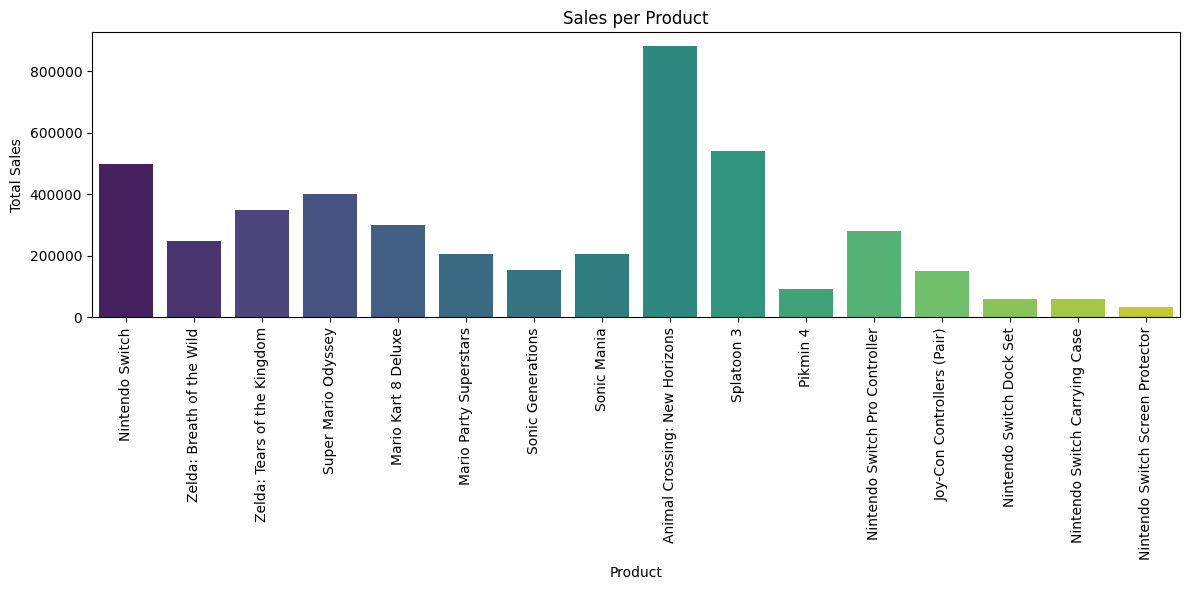

In [41]:
# PLOT GRAPHS occurence of sales per product 
import matplotlib.pyplot as plt
import seaborn as sns
# Sum the sales for each product
sales_per_product = df_cooccurrence.set_index('Product').sum(axis=1)
# Plot the sales per product
plt.figure(figsize=(12, 6))
sns.barplot(x=sales_per_product.index, y=sales_per_product.values, palette="viridis")
plt.xticks(rotation=90)
plt.title('Sales per Product')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

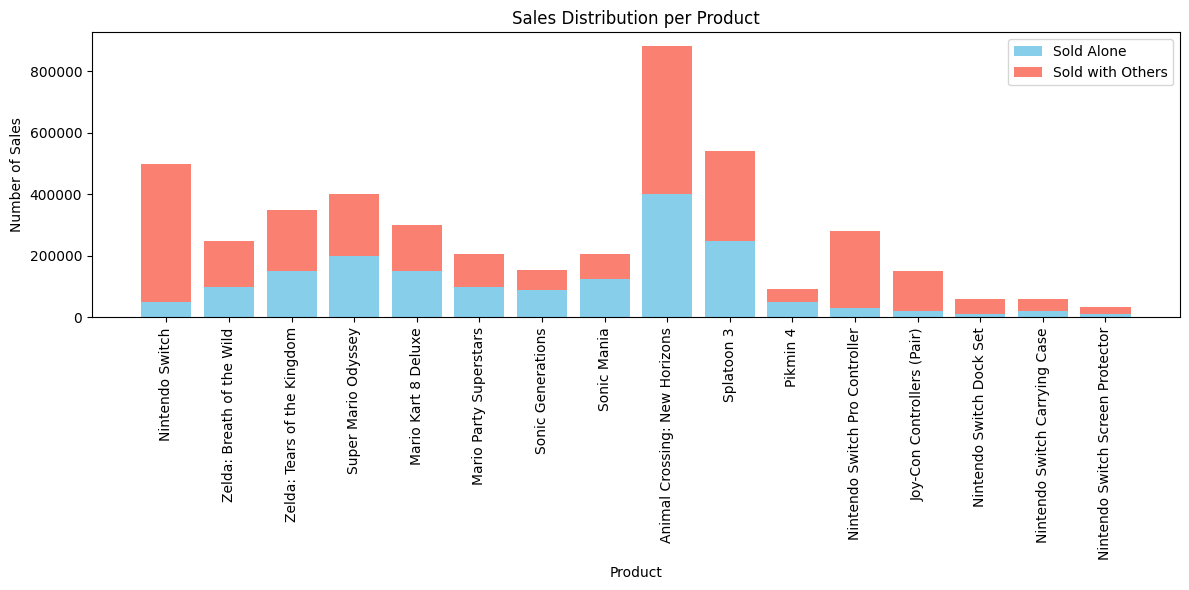

In [43]:
# PLot number of times product sold alone (dional) and when sold with other produc (non.diogonal)
diagonal_sales = df_cooccurrence.set_index('Product').values.diagonal()
non_diagonal_sales = sales_per_product.values - diagonal_sales
labels = df_cooccurrence['Product']
x = range(len(labels))
plt.figure(figsize=(12, 6))
plt.bar(x, diagonal_sales, label='Sold Alone', color='skyblue')
plt.bar(x, non_diagonal_sales, bottom=diagonal_sales, label='Sold with Others', color='salmon')
plt.xticks(x, labels, rotation=90)
plt.title('Sales Distribution per Product')
plt.xlabel('Product')
plt.ylabel('Number of Sales')
plt.legend()
plt.tight_layout()
plt.show()

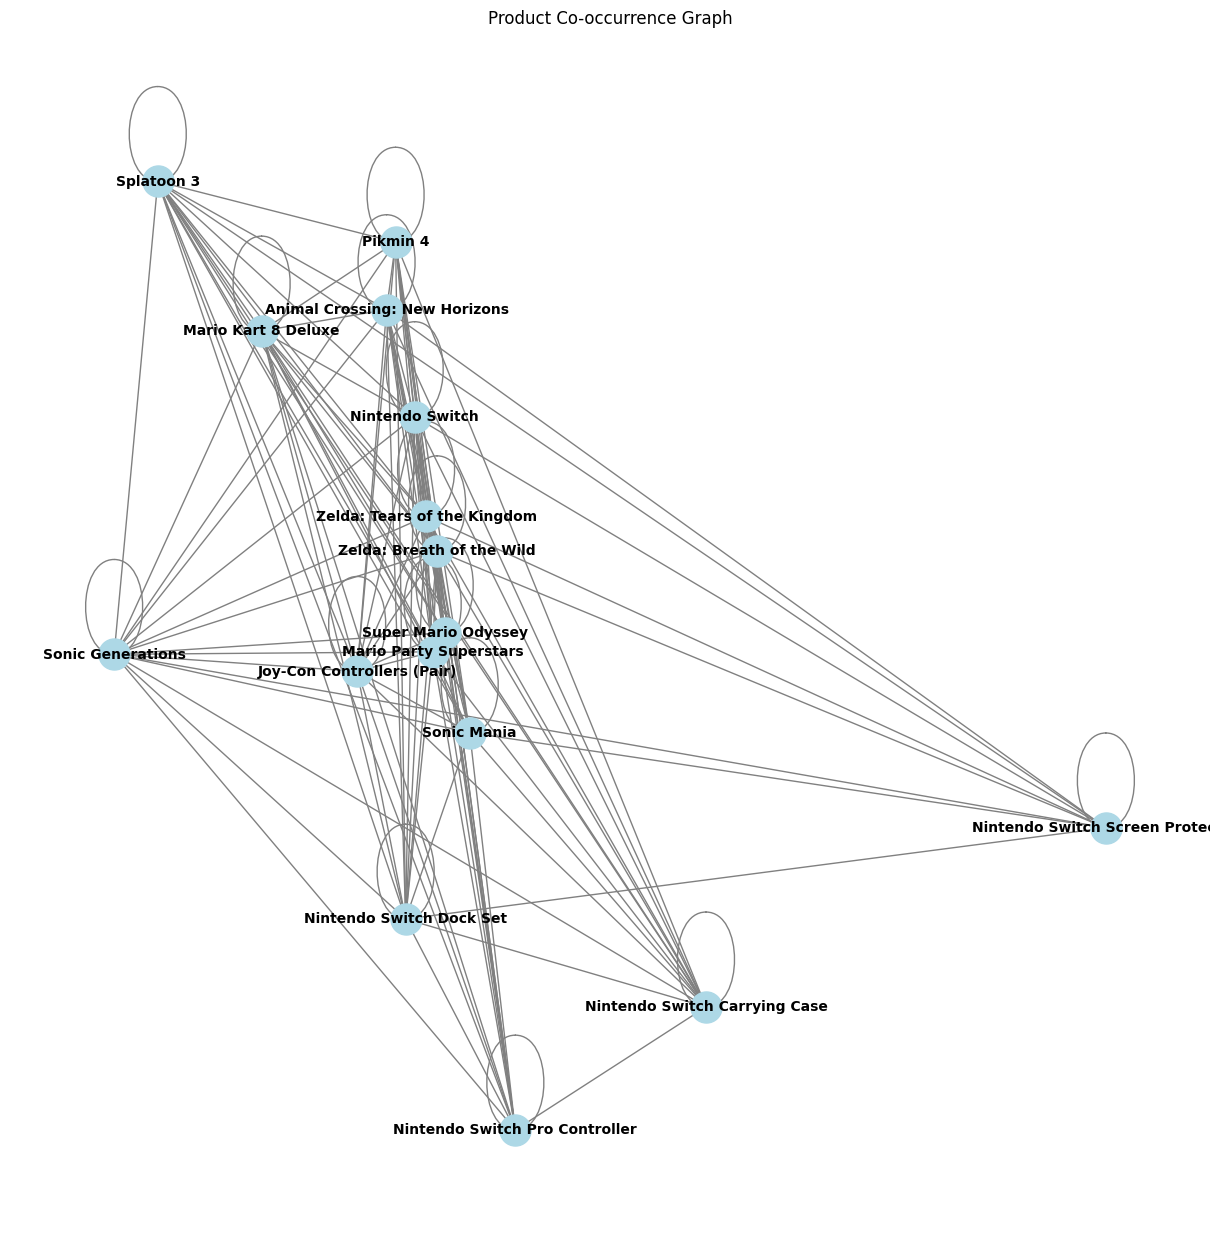

In [123]:
# Graphic analysis about co-occurence between products
import networkx as nx
# Create a graph from the co-occurrence matrix
G = nx.from_pandas_adjacency(df_cooccurrence.set_index('Product'))
# Draw the graph    
plt.figure(figsize=(12, 12))
pos = nx.spring_layout(G, k=0.15, iterations=20)
nx.draw(G, pos, with_labels=True, node_size=500, node_color='lightblue', font_size=10, font_weight='bold', edge_color='gray')
plt.title('Product Co-occurrence Graph')
plt.show()  

In [125]:
# Create a conditional_prob matrix based on co-occurence matrix
cooccurrence_matrix = df_cooccurrence.set_index('Product').values
# Calculate the sum of each row
row_sums = cooccurrence_matrix.sum(axis=1, keepdims=True)
# Avoid division by zero
row_sums[row_sums == 0] = 1
# Calculate the conditional probability matrix
conditional_prob_matrix = cooccurrence_matrix / row_sums
# Convert back to DataFrame for easier handling
conditional_prob_df = pd.DataFrame(conditional_prob_matrix, index=df_cooccurrence['Product'], columns=df_cooccurrence['Product'])
conditional_prob_df

Product,Nintendo Switch,Zelda: Breath of the Wild,Zelda: Tears of the Kingdom,Super Mario Odyssey,Mario Kart 8 Deluxe,Mario Party Superstars,Sonic Generations,Sonic Mania,Animal Crossing: New Horizons,Splatoon 3,Pikmin 4,Nintendo Switch Pro Controller,Joy-Con Controllers (Pair),Nintendo Switch Dock Set,Nintendo Switch Carrying Case,Nintendo Switch Screen Protector
Product,,,,,,,,,,,,,,,,
Nintendo Switch,0.100000,0.060000,0.100000,0.120000,0.080000,0.040000,0.020000,0.020000,0.200000,0.060000,0.010000,0.100000,0.040000,0.020000,0.020000,0.010000
Zelda: Breath of the Wild,0.120000,0.400000,0.080000,0.060000,0.040000,0.020000,0.008000,0.012000,0.120000,0.080000,0.008000,0.020000,0.012000,0.008000,0.008000,0.004000
Zelda: Tears of the Kingdom,0.142857,0.057143,0.428571,0.071429,0.042857,0.028571,0.014286,0.014286,0.085714,0.057143,0.005714,0.028571,0.008571,0.005714,0.005714,0.002857
Super Mario Odyssey,0.150000,0.037500,0.062500,0.500000,0.075000,0.050000,0.012500,0.012500,0.062500,0.025000,0.005000,0.005000,0.002500,0.000000,0.000000,0.000000
Mario Kart 8 Deluxe,0.133333,0.033333,0.050000,0.100000,0.500000,0.033333,0.006667,0.010000,0.043333,0.050000,0.003333,0.016667,0.010000,0.006667,0.003333,0.000000
Mario Party Superstars,0.097561,0.024390,0.048780,0.097561,0.048780,0.487805,0.009756,0.014634,0.073171,0.048780,0.004878,0.024390,0.009756,0.004878,0.004878,0.000000
Sonic Generations,0.064516,0.012903,0.032258,0.032258,0.012903,0.012903,0.580645,0.064516,0.064516,0.064516,0.006452,0.019355,0.012903,0.006452,0.006452,0.006452
Sonic Mania,0.048077,0.014423,0.024038,0.024038,0.014423,0.014423,0.048077,0.600962,0.096154,0.072115,0.004808,0.014423,0.009615,0.004808,0.004808,0.004808
Animal Crossing: New Horizons,0.113250,0.033975,0.033975,0.028313,0.014723,0.016988,0.011325,0.022650,0.453001,0.056625,0.011325,0.113250,0.056625,0.011325,0.011325,0.011325


/var/folders/2_/w4w00tzx0r975_q9mkp6skxr0000gp/T/ipykernel_2618/554601135.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conditional_prob_df.columns, y=conditional_prob_df.loc[product_name], palette="magma")


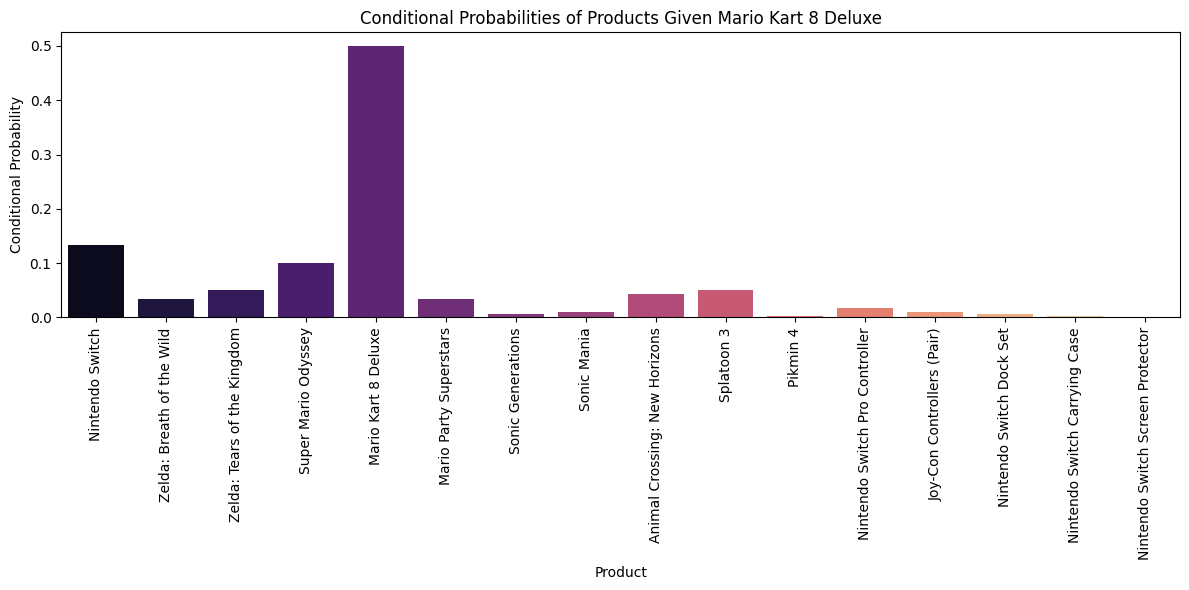

In [126]:
# Bar plot of conditional probabilities for a specific product
product_name = 'Mario Kart 8 Deluxe'
if product_name in conditional_prob_df.index:
    plt.figure(figsize=(12, 6))
    sns.barplot(x=conditional_prob_df.columns, y=conditional_prob_df.loc[product_name], palette="magma")
    plt.xticks(rotation=90)
    plt.title(f'Conditional Probabilities of Products Given {product_name}')
    plt.xlabel('Product')
    plt.ylabel('Conditional Probability')
    plt.tight_layout()
    plt.show()
else:
    print(f"Product '{product_name}' not found in the conditional probability matrix.")

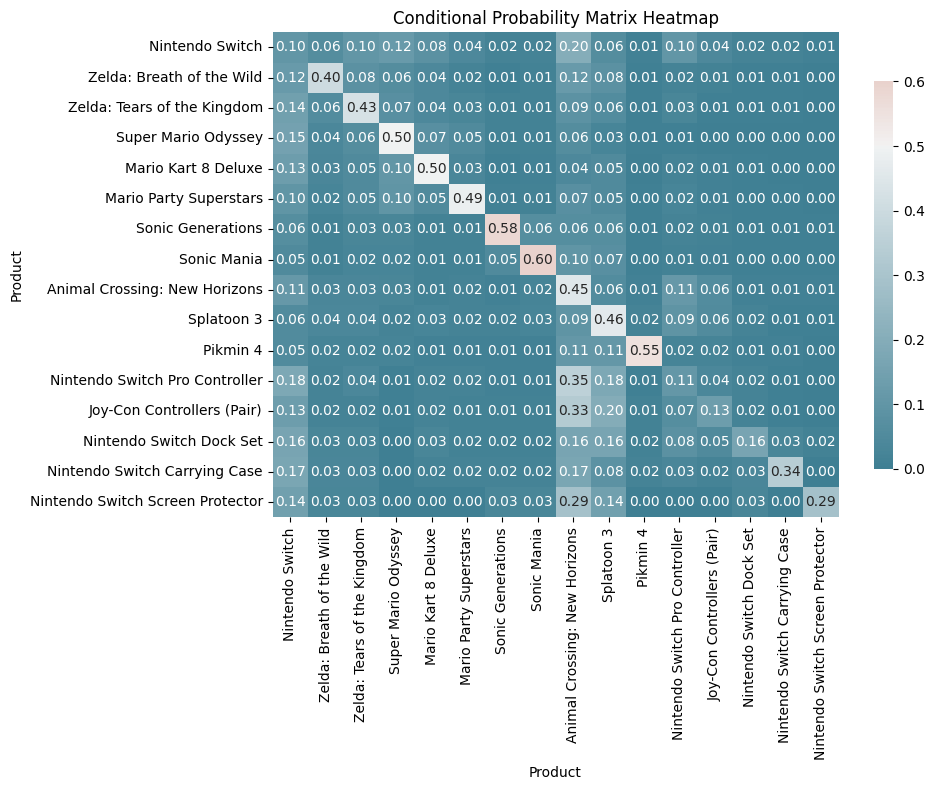

In [127]:
# Color code conditional_prob_df to understand higher and lower correlations between products 
import numpy as np
# Create a color-coded matrix
plt.figure(figsize=(10, 8))
cmap = sns.diverging_palette(220, 20, as_cmap=True)
sns.heatmap(conditional_prob_df, cmap=cmap, center=0.5, annot=True, fmt=".2f", cbar_kws={"shrink": .8})
plt.title('Conditional Probability Matrix Heatmap')
plt.tight_layout()
plt.show()

# Creation of Table mimic what might me found in a Database with milions of products 

In [46]:
# 1. PRODUCTS TABLE - Main product information
products_list = []
for category, items in data_json.items():
    for item in items:
        product = {
            'product_id': None,  # Will assign later
            'name': item['name'],
            'category': item.get('category', category),
            'main_category': category,
            'type': item.get('type'),
            'franchise': item.get('franchise'),
            'min_age': item.get('min_age'),
            'release_date': item.get('release_date'),
            'times_sold': item.get('times_sold')
        }
        products_list.append(product)

products_df_description = pd.DataFrame(products_list)
products_df_description['product_id'] = range(1, len(products_df_description) + 1)
products_df_description = products_df_description[['product_id', 'name', 'category', 'main_category', 'type',
                                                   'franchise', 'min_age', 'release_date', 'times_sold']]

print("PRODUCTS TABLE")
products_df_description

PRODUCTS TABLE


,product_id,name,category,main_category,type,franchise,min_age,release_date,times_sold
0,1,Nintendo Switch,Console,Console,None,None,NaN,None,500000
1,2,Zelda: Breath of the Wild,Game,Games,Adventure,The Legend of Zelda,12.0,2017-03-03,250000
2,3,Zelda: Tears of the Kingdom,Game,Games,Adventure,The Legend of Zelda,12.0,2023-05-12,350000
3,4,Super Mario Odyssey,Game,Games,Platformer,Super Mario,7.0,2017-10-27,400000
4,5,Mario Kart 8 Deluxe,Game,Games,Racing,Super Mario,6.0,2017-04-28,300000
5,6,Mario Party Superstars,Game,Games,Party,Super Mario,6.0,2021-10-29,200000
6,7,Sonic Generations,Game,Games,Platformer,Sonic,10.0,2011-11-01,180000
7,8,Sonic Mania,Game,Games,Platformer,Sonic,10.0,2017-08-15,250000
8,9,Animal Crossing: New Horizons,Game,Games,Simulation,Animal Crossing,3.0,2020-03-20,800000
9,10,Splatoon 3,Game,Games,Shooter,Splatoon,10.0,2022-09-09,500000


In [47]:
# 2. INVENTORY TABLE - Store-level stock/sales data
inventory_list = []
for category, items in data_json.items():
    for item in items:
        product_name = item['name']
        # Get product_id
        product_id = products_df_description[products_df_description['name'] == product_name]['product_id'].values[0]
        
        for store in ['Store A', 'Store B', 'Store C']:
            if store in item:
                stock = item[store]
                if stock is not None:  # Only add if there's data
                    inventory_list.append({
                        'inventory_id': None,
                        'product_id': product_id,
                        'product_name': product_name,
                        'store_name': store,
                        'stock_sold': stock
                    })

df_inventory = pd.DataFrame(inventory_list)
df_inventory['inventory_id'] = range(1, len(df_inventory) + 1)
df_inventory = df_inventory[['inventory_id', 'product_id', 'product_name', 'store_name', 'stock_sold']]

print("\nINVENTORY TABLE")
df_inventory    


INVENTORY TABLE


,inventory_id,product_id,product_name,store_name,stock_sold
0,1,1,Nintendo Switch,Store A,200000
1,2,1,Nintendo Switch,Store B,150000
2,3,1,Nintendo Switch,Store C,150000
3,4,2,Zelda: Breath of the Wild,Store A,120000
4,5,2,Zelda: Breath of the Wild,Store B,80000
5,6,2,Zelda: Breath of the Wild,Store C,50000
6,7,3,Zelda: Tears of the Kingdom,Store A,200000
7,8,3,Zelda: Tears of the Kingdom,Store B,100000
8,9,3,Zelda: Tears of the Kingdom,Store C,50000
9,10,4,Super Mario Odyssey,Store A,150000


In [48]:
# 3. PRODUCT_RELATIONSHIPS TABLE - From co-occurrence matrix
relationships_list = []
relationship_id = 1

for idx, row in df_cooccurrence.iterrows():
    product_a = row['Product']
    # Get product_id for product_a
    product_a_id = products_df_description[products_df_description['name'] == product_a]['product_id'].values
    
    if len(product_a_id) == 0:
        continue
    
    product_a_id = product_a_id[0]
    
    for col in df_cooccurrence.columns:
        if col != 'Product':
            cooccurrence_score = row[col]
            if pd.notna(cooccurrence_score) and cooccurrence_score > 0:
                # Get product_id for product_b
                product_b_id = products_df_description[products_df_description['name'] == col]['product_id'].values
                
                if len(product_b_id) > 0:
                    relationships_list.append({
                        'relationship_id': relationship_id,
                        'product_a_id': product_a_id,
                        'product_a_name': product_a,
                        'product_b_id': product_b_id[0],
                        'product_b_name': col,
                        'cooccurrence_score': cooccurrence_score,
                        'relationship_type': 'frequently_bought_together'
                    })
                    relationship_id += 1

df_relationships = pd.DataFrame(relationships_list)

print("\nPRODUCT_RELATIONSHIPS TABLE")
df_relationships


PRODUCT_RELATIONSHIPS TABLE


,relationship_id,product_a_id,product_a_name,product_b_id,product_b_name,cooccurrence_score,relationship_type
0,1,1,Nintendo Switch,1,Nintendo Switch,50000,frequently_bought_together
1,2,1,Nintendo Switch,2,Zelda: Breath of the Wild,30000,frequently_bought_together
2,3,1,Nintendo Switch,3,Zelda: Tears of the Kingdom,50000,frequently_bought_together
3,4,1,Nintendo Switch,4,Super Mario Odyssey,60000,frequently_bought_together
4,5,1,Nintendo Switch,5,Mario Kart 8 Deluxe,40000,frequently_bought_together
...,...,...,...,...,...,...,...
233,234,16,Nintendo Switch Screen Protector,8,Sonic Mania,1000,frequently_bought_together
234,235,16,Nintendo Switch Screen Protector,9,Animal Crossing: New Horizons,10000,frequently_bought_together
235,236,16,Nintendo Switch Screen Protector,10,Splatoon 3,5000,frequently_bought_together
236,237,16,Nintendo Switch Screen Protector,14,Nintendo Switch Dock Set,1000,frequently_bought_together


In [49]:
# 4. SUMMARY STATISTICS - Aggregate views for analytics
print("=" * 80)
print("DATABASE SCHEMA SUMMARY")
print("=" * 80)

tables_info = {
    'PRODUCTS': {
        'rows': len(products_df_description),
        'columns': list(products_df_description.columns),
        'primary_key': 'product_id',
        'description': 'Master product catalog'
    },
    'INVENTORY': {
        'rows': len(df_inventory),
        'columns': list(df_inventory.columns),
        'primary_key': 'inventory_id',
        'foreign_keys': ['product_id -> PRODUCTS.product_id'],
        'description': 'Store-level inventory and sales'
    },
    'PRODUCT_RELATIONSHIPS': {
        'rows': len(df_relationships),
        'columns': list(df_relationships.columns),
        'primary_key': 'relationship_id',
        'foreign_keys': [
            'product_a_id -> PRODUCTS.product_id',
            'product_b_id -> PRODUCTS.product_id'
        ],
        'description': 'Product co-occurrence and associations'
    }
}

for table_name, info in tables_info.items():
    print(f"\n{table_name}:")
    print(f"  Rows: {info['rows']}")
    print(f"  Columns: {', '.join(info['columns'])}")
    print(f"  Primary Key: {info['primary_key']}")
    if 'foreign_keys' in info:
        print(f"  Foreign Keys: {', '.join(info['foreign_keys'])}")
    print(f"  Description: {info['description']}")

DATABASE SCHEMA SUMMARY

PRODUCTS:
  Rows: 16
  Columns: product_id, name, category, main_category, type, franchise, min_age, release_date, times_sold
  Primary Key: product_id
  Description: Master product catalog

INVENTORY:
  Rows: 44
  Columns: inventory_id, product_id, product_name, store_name, stock_sold
  Primary Key: inventory_id
  Foreign Keys: product_id -> PRODUCTS.product_id
  Description: Store-level inventory and sales

PRODUCT_RELATIONSHIPS:
  Rows: 238
  Columns: relationship_id, product_a_id, product_a_name, product_b_id, product_b_name, cooccurrence_score, relationship_type
  Primary Key: relationship_id
  Foreign Keys: product_a_id -> PRODUCTS.product_id, product_b_id -> PRODUCTS.product_id
  Description: Product co-occurrence and associations


# Create a new format of data create a descrirption per product 

In [88]:
import pandas as pd
import json
from typing import List, Dict
import chromadb
from chromadb.config import Settings
from sentence_transformers import SentenceTransformer

# Load the data
with open('challenge/dataset.json', 'r') as f:
    data_json = json.load(f)

# Flatten the JSON structure into a list of products
products = []
for category, items in data_json.items():
    for item in items:
        item['main_category'] = category
        products.append(item)

# Create a DataFrame for easier manipulation
df_products = pd.DataFrame(products)
print(f"Total products: {len(df_products)}")

# Change Nan in Store A B or C to 0
df_products['Store A'] = df_products['Store A'].fillna(0)
df_products['Store B'] = df_products['Store B'].fillna(0)
df_products['Store C'] = df_products['Store C'].fillna(0)
df_products

Total products: 16


,name,Store A,Store B,Store C,category,times_sold,main_category,release_date,type,franchise,min_age
0,Nintendo Switch,200000,150000.0,150000.0,Console,500000,Console,NaN,NaN,NaN,NaN
1,Zelda: Breath of the Wild,120000,80000.0,50000.0,Game,250000,Games,2017-03-03,Adventure,The Legend of Zelda,12.0
2,Zelda: Tears of the Kingdom,200000,100000.0,50000.0,Game,350000,Games,2023-05-12,Adventure,The Legend of Zelda,12.0
3,Super Mario Odyssey,150000,100000.0,150000.0,Game,400000,Games,2017-10-27,Platformer,Super Mario,7.0
4,Mario Kart 8 Deluxe,100000,100000.0,100000.0,Game,300000,Games,2017-04-28,Racing,Super Mario,6.0
5,Mario Party Superstars,80000,70000.0,50000.0,Game,200000,Games,2021-10-29,Party,Super Mario,6.0
6,Sonic Generations,60000,60000.0,60000.0,Game,180000,Games,2011-11-01,Platformer,Sonic,10.0
7,Sonic Mania,150000,100000.0,0.0,Game,250000,Games,2017-08-15,Platformer,Sonic,10.0
8,Animal Crossing: New Horizons,500000,300000.0,0.0,Game,800000,Games,2020-03-20,Simulation,Animal Crossing,3.0
9,Splatoon 3,200000,150000.0,150000.0,Game,500000,Games,2022-09-09,Shooter,Splatoon,10.0


In [91]:
# Create rich text descriptions for each product (for better RAG retrieval)
def create_product_description(product: Dict) -> str:
    """
    Create a detailed text description for embedding
    """
    desc_parts = [f"Product: {product['name']}"]
    
    # Category and type
    desc_parts.append(f"Category: {product.get('main_category', 'Unknown')}")
    if 'type' in product:
        desc_parts.append(f"Type: {product['type']}")
    
    # Game-specific info
    if 'franchise' in product:
        desc_parts.append(f"Franchise: {product['franchise']}")
    if 'min_age' in product:
        desc_parts.append(f"Suitable for ages {product['min_age']}+")
    if 'release_date' in product:
        desc_parts.append(f"Released: {product['release_date']}")
    
    # Popularity
    desc_parts.append(f"Total sales: {product.get('times_sold', 0)}")
    
    # Store availability
    stores = []
    for store in ['Store A', 'Store B', 'Store C']:
        if store in product and product[store] not in [None, 0]:
            stores.append(store)
    if stores:
        desc_parts.append(f"Sold at: {', '.join(stores)}")
    
    
    return ". ".join(desc_parts) + "."

# Add descriptions to dataframe
df_products['description'] = df_products.apply(
    lambda row: create_product_description(row.to_dict()), 
    axis=1
)

print("Sample description:")
df_products['description'].iloc[0]

Sample description:


'Product: Nintendo Switch. Category: Console. Type: nan. Franchise: nan. Suitable for ages nan+. Released: nan. Total sales: 500000. Sold at: Store A, Store B, Store C.'

In [92]:
df_products

,name,Store A,Store B,Store C,category,times_sold,main_category,release_date,type,franchise,min_age,description
0,Nintendo Switch,200000,150000.0,150000.0,Console,500000,Console,NaN,NaN,NaN,NaN,Product: Nintendo Switch. Category: Console. T...
1,Zelda: Breath of the Wild,120000,80000.0,50000.0,Game,250000,Games,2017-03-03,Adventure,The Legend of Zelda,12.0,Product: Zelda: Breath of the Wild. Category: ...
2,Zelda: Tears of the Kingdom,200000,100000.0,50000.0,Game,350000,Games,2023-05-12,Adventure,The Legend of Zelda,12.0,Product: Zelda: Tears of the Kingdom. Category...
3,Super Mario Odyssey,150000,100000.0,150000.0,Game,400000,Games,2017-10-27,Platformer,Super Mario,7.0,Product: Super Mario Odyssey. Category: Games....
4,Mario Kart 8 Deluxe,100000,100000.0,100000.0,Game,300000,Games,2017-04-28,Racing,Super Mario,6.0,Product: Mario Kart 8 Deluxe. Category: Games....
5,Mario Party Superstars,80000,70000.0,50000.0,Game,200000,Games,2021-10-29,Party,Super Mario,6.0,Product: Mario Party Superstars. Category: Gam...
6,Sonic Generations,60000,60000.0,60000.0,Game,180000,Games,2011-11-01,Platformer,Sonic,10.0,Product: Sonic Generations. Category: Games. T...
7,Sonic Mania,150000,100000.0,0.0,Game,250000,Games,2017-08-15,Platformer,Sonic,10.0,Product: Sonic Mania. Category: Games. Type: P...
8,Animal Crossing: New Horizons,500000,300000.0,0.0,Game,800000,Games,2020-03-20,Simulation,Animal Crossing,3.0,Product: Animal Crossing: New Horizons. Catego...
9,Splatoon 3,200000,150000.0,150000.0,Game,500000,Games,2022-09-09,Shooter,Splatoon,10.0,Product: Splatoon 3. Category: Games. Type: Sh...


In [103]:
from sentence_transformers import SentenceTransformer

def create_embeddings_table(model, df_products, table_products):
    """
    Store product descriptions for semantic search
    This would contain embeddings in production (vectors)
    """
    embeddings = table_products[['product_id', 'name']].copy()
    embeddings['description'] = df_products['description'].values
    embeddings['embedding_model'] = 'all-MiniLM-L6-v2'
    
    # Generate embeddings
    embedding_vectors = model.encode(embeddings['description'].tolist())
    
    # Store embeddings as a list (each row contains one array)
    # This converts each row of the 2D array into a list stored in the cell
    embeddings['embedding_vector'] = list(embedding_vectors)
    
    # Add metadata
    embeddings['embedding_dimension'] = len(embedding_vectors[0])
    embeddings['last_updated'] = pd.Timestamp.now()
    
    return embeddings

model = SentenceTransformer('all-MiniLM-L6-v2')
table_embeddings = create_embeddings_table(model, df_products, products_df_description)

print("\nPRODUCT_EMBEDDINGS")
# print product 1 description followed by embedding
print(table_embeddings['description'].iloc[0])
print(table_embeddings['embedding_vector'].iloc[0])
table_embeddings



PRODUCT_EMBEDDINGS
Product: Nintendo Switch. Category: Console. Type: nan. Franchise: nan. Suitable for ages nan+. Released: nan. Total sales: 500000. Sold at: Store A, Store B, Store C.
[-2.15183850e-02 -7.27605149e-02 -6.19373797e-03 -7.57616013e-02
 -5.89287654e-02  2.76871375e-03  9.09370258e-02  6.85392171e-02
  2.41735275e-03  6.91074952e-02  9.51910391e-02 -1.41260047e-02
  1.01646120e-02  2.08621100e-03  9.06400476e-03 -3.63020934e-02
 -1.44528840e-02 -1.24978032e-02  4.13890667e-02 -6.89541921e-02
  6.38004318e-02 -2.38845404e-02 -1.36074573e-02  4.59550321e-02
 -5.60671352e-02  2.81396285e-02 -5.95677234e-02 -4.14962135e-02
  4.23431490e-03 -4.33184505e-02 -1.15955077e-01  4.89519872e-02
  3.23390178e-02 -4.27805297e-02 -1.51279736e-02  4.30805748e-03
  2.59845946e-02  8.02020077e-03 -4.60296907e-02 -6.83620349e-02
 -6.07152581e-02 -2.44957488e-02  4.85912859e-02 -2.72458699e-02
  2.96779647e-02  3.95077728e-02 -4.42534545e-03 -3.79956700e-02
  3.24345268e-02  2.56490689e-02

,product_id,name,description,embedding_model,embedding_vector,embedding_dimension,last_updated
0,1,Nintendo Switch,Product: Nintendo Switch. Category: Console. T...,all-MiniLM-L6-v2,"[-0.021518385, -0.072760515, -0.006193738, -0....",384,2025-12-21 18:49:11.214735
1,2,Zelda: Breath of the Wild,Product: Zelda: Breath of the Wild. Category: ...,all-MiniLM-L6-v2,"[0.008585584, 0.0049917833, -0.015300389, -0.0...",384,2025-12-21 18:49:11.214735
2,3,Zelda: Tears of the Kingdom,Product: Zelda: Tears of the Kingdom. Category...,all-MiniLM-L6-v2,"[-0.009858992, 0.0033193228, 0.030708559, -0.0...",384,2025-12-21 18:49:11.214735
3,4,Super Mario Odyssey,Product: Super Mario Odyssey. Category: Games....,all-MiniLM-L6-v2,"[-0.019535478, -0.008027681, 0.001384378, -0.0...",384,2025-12-21 18:49:11.214735
4,5,Mario Kart 8 Deluxe,Product: Mario Kart 8 Deluxe. Category: Games....,all-MiniLM-L6-v2,"[-0.03894265, 0.035233296, 0.0066673174, 0.012...",384,2025-12-21 18:49:11.214735
5,6,Mario Party Superstars,Product: Mario Party Superstars. Category: Gam...,all-MiniLM-L6-v2,"[-0.038930982, -0.0081367595, -0.011600026, -0...",384,2025-12-21 18:49:11.214735
6,7,Sonic Generations,Product: Sonic Generations. Category: Games. T...,all-MiniLM-L6-v2,"[-0.020957863, -0.06849025, 0.05440982, -0.078...",384,2025-12-21 18:49:11.214735
7,8,Sonic Mania,Product: Sonic Mania. Category: Games. Type: P...,all-MiniLM-L6-v2,"[-0.00449438, -0.04098549, 0.026130086, -0.088...",384,2025-12-21 18:49:11.214735
8,9,Animal Crossing: New Horizons,Product: Animal Crossing: New Horizons. Catego...,all-MiniLM-L6-v2,"[-0.004370354, -0.091734715, 0.030614272, -0.0...",384,2025-12-21 18:49:11.214735
9,10,Splatoon 3,Product: Splatoon 3. Category: Games. Type: Sh...,all-MiniLM-L6-v2,"[-0.03698483, -0.08521286, -0.021686593, -0.05...",384,2025-12-21 18:49:11.214735


In [83]:
table_embeddings

,product_id,name,description,embedding_model,embedding_vector,embedding_dimension,last_updated
0,1,Nintendo Switch,Product: Nintendo Switch. Category: Console. T...,all-MiniLM-L6-v2,"[-0.022849036, -0.0725543, -0.0067022084, -0.0...",384,2025-12-21 15:27:44.281092
1,2,Zelda: Breath of the Wild,Product: Zelda: Breath of the Wild. Category: ...,all-MiniLM-L6-v2,"[0.0060449783, 0.0035647738, -0.011715921, -0....",384,2025-12-21 15:27:44.281092
2,3,Zelda: Tears of the Kingdom,Product: Zelda: Tears of the Kingdom. Category...,all-MiniLM-L6-v2,"[-0.010553052, 0.0012471965, 0.034349322, -0.0...",384,2025-12-21 15:27:44.281092
3,4,Super Mario Odyssey,Product: Super Mario Odyssey. Category: Games....,all-MiniLM-L6-v2,"[-0.022038063, -0.0116833905, 0.0037281031, -0...",384,2025-12-21 15:27:44.281092
4,5,Mario Kart 8 Deluxe,Product: Mario Kart 8 Deluxe. Category: Games....,all-MiniLM-L6-v2,"[-0.038961682, 0.031981327, 0.007750093, 0.007...",384,2025-12-21 15:27:44.281092
5,6,Mario Party Superstars,Product: Mario Party Superstars. Category: Gam...,all-MiniLM-L6-v2,"[-0.038844332, -0.009340005, -0.009900515, -0....",384,2025-12-21 15:27:44.281092
6,7,Sonic Generations,Product: Sonic Generations. Category: Games. T...,all-MiniLM-L6-v2,"[-0.021197518, -0.07105315, 0.058179688, -0.08...",384,2025-12-21 15:27:44.281092
7,8,Sonic Mania,Product: Sonic Mania. Category: Games. Type: P...,all-MiniLM-L6-v2,"[-0.006092884, -0.04422172, 0.029790943, -0.09...",384,2025-12-21 15:27:44.281092
8,9,Animal Crossing: New Horizons,Product: Animal Crossing: New Horizons. Catego...,all-MiniLM-L6-v2,"[-0.003906727, -0.09655724, 0.032768458, -0.04...",384,2025-12-21 15:27:44.281092
9,10,Splatoon 3,Product: Splatoon 3. Category: Games. Type: Sh...,all-MiniLM-L6-v2,"[-0.036671918, -0.08854304, -0.016684767, -0.0...",384,2025-12-21 15:27:44.281092


# Store Data in JSON FORMAT :
## Easier to agreggape MOST valuable info --> ID , Text Description , Metadata

In [104]:
def create_products_json(df_products, products_df_description):
    """
    Create optimized products JSON structure with clean null handling
    """
    products_data = {
        "metadata": {
            "version": "1.0",
            "created_at": pd.Timestamp.now().isoformat(),
            "total_products": len(df_products),
            "embedding_model": "all-MiniLM-L6-v2",
            "description": "Nintendo products catalog for RAG system"
        },
        "products": []
    }
    
    for idx, row in df_products.iterrows():
        # Get additional info from products_df_description
        product_details = products_df_description[
            products_df_description['name'] == row['name']
        ].iloc[0]
        
        # Build clean description (without None/NaN values)
        desc_parts = [f"Product: {row['name']}"]
        
        # Category (always present)
        desc_parts.append(f"Category: {row.get('main_category', 'Unknown')}")
        
        # Type (only if available)
        if pd.notna(row.get('type')) and row.get('type') != 'Unknown':
            desc_parts.append(f"Type: {row['type']}")
        else:
            desc_parts.append("Type: Unavailable")
        
        # Franchise (only if available)
        if pd.notna(row.get('franchise')):
            desc_parts.append(f"Franchise: {row['franchise']}")
        else:
            desc_parts.append("Franchise: Unavailable") 
        
        # Min age (only if available, otherwise mark as unavailable)
        if pd.notna(row.get('min_age')) and row.get('min_age') != 0:
            desc_parts.append(f"Age rating: {int(row['min_age'])}")
        else:
            desc_parts.append("Age rating: Unavailable")
        
        # Release date (only if available)
        if pd.notna(row.get('release_date')):
            desc_parts.append(f"Released: {row['release_date']}")
        else:
            desc_parts.append("Release date: Unavailable")
        
        # Popularity
        desc_parts.append(f"Total sales: {row.get('times_sold', 0):,}")
        
        # Store availability
        stores = [
            store for store in ['Store A', 'Store B', 'Store C']
            if store in row and pd.notna(row[store]) and row[store] > 0
        ]
        if stores:
            desc_parts.append(f"Available at: {', '.join(stores)}")
        else:
            desc_parts.append("Store availability: Unavailable")
        
        clean_description = ". ".join(desc_parts) + "."
        
        # Build metadata with proper null handling
        product = {
            "id": f"prod_{product_details['product_id']:04d}",  # e.g., prod_0001
            "text": clean_description,  # Clean text for embedding
            "metadata": {
                # Core identifiers (never null)
                "name": str(row['name']),
                "product_id": int(product_details['product_id']),
                
                # Categories (never null, default to 'Unknown')
                "category": str(row.get('category', 'Unknown')),
                "main_category": str(row.get('main_category', 'Unknown')),
                
                # Type (null if not available)
                "type": (
                    str(row['type']) 
                    if pd.notna(row.get('type')) and row.get('type') != 'Unknown' 
                    else None
                ),
                
                # Game info (null if not available)
                "franchise": (
                    str(row['franchise']) 
                    if pd.notna(row.get('franchise')) 
                    else None
                ),
                
                # Min age (null if not available or 0)
                "min_age": (
                    int(row['min_age']) 
                    if pd.notna(row.get('min_age')) and row.get('min_age') > 0 
                    else None
                ),
                
                # Release date (null if not available)
                "release_date": (
                    str(row['release_date']) 
                    if pd.notna(row.get('release_date')) 
                    else None
                ),
                
                # Business metrics (never null, default to 0)
                "times_sold": int(row.get('times_sold', 0)),
                "times_sold_Store_A": int(row.get('Store A', 0)),
                "times_sold_Store_B": int(row.get('Store B', 0)),
                "times_sold_Store_C": int(row.get('Store C', 0)),
                "popularity_rank": None,  # Will calculate later
                
                # Store availability
                "available_stores": stores if stores else [],
                "total_stock": sum([
                    int(row.get(store, 0)) 
                    for store in ['Store A', 'Store B', 'Store C']
                    if pd.notna(row.get(store))
                ]),
                "is_available": len(stores) > 0,

                # Store correlation
                "store_strength_Store_A": int(row.get('Store A', 0)) / int(row.get('times_sold', 0)),
                "store_strength_Store_B": int(row.get('Store B', 0)) / int(row.get('times_sold', 0)),
                "store_strength_Store_C": int(row.get('Store C', 0)) / int(row.get('times_sold', 0))
            }
        }
        
        products_data["products"].append(product)
    
    # Calculate popularity ranks
    sorted_products = sorted(
        products_data["products"], 
        key=lambda x: x["metadata"]["times_sold"], 
        reverse=True
    )
    for rank, product in enumerate(sorted_products, 1):
        product["metadata"]["popularity_rank"] = rank
    
    return products_data

# Create products JSON with clean nulls
products_json = create_products_json(df_products, products_df_description)

# Save to file
with open('challenge/products_rag.json', 'w', encoding='utf-8') as f:
    json.dump(products_json, f, indent=2, ensure_ascii=False)

# To dataframe to visualize
df_products_rag = pd.json_normalize(products_json["products"])
df_products_rag.head()


,id,text,metadata.name,metadata.product_id,metadata.category,metadata.main_category,metadata.type,metadata.franchise,metadata.min_age,metadata.release_date,...,metadata.times_sold_Store_A,metadata.times_sold_Store_B,metadata.times_sold_Store_C,metadata.popularity_rank,metadata.available_stores,metadata.total_stock,metadata.is_available,metadata.store_strength_Store_A,metadata.store_strength_Store_B,metadata.store_strength_Store_C
0,prod_0001,Product: Nintendo Switch. Category: Console. T...,Nintendo Switch,1,Console,Console,None,None,NaN,None,...,200000,150000,150000,2,"[Store A, Store B, Store C]",500000,True,0.400000,0.300000,0.300000
1,prod_0002,Product: Zelda: Breath of the Wild. Category: ...,Zelda: Breath of the Wild,2,Game,Games,Adventure,The Legend of Zelda,12.0,2017-03-03,...,120000,80000,50000,7,"[Store A, Store B, Store C]",250000,True,0.480000,0.320000,0.200000
2,prod_0003,Product: Zelda: Tears of the Kingdom. Category...,Zelda: Tears of the Kingdom,3,Game,Games,Adventure,The Legend of Zelda,12.0,2023-05-12,...,200000,100000,50000,5,"[Store A, Store B, Store C]",350000,True,0.571429,0.285714,0.142857
3,prod_0004,Product: Super Mario Odyssey. Category: Games....,Super Mario Odyssey,4,Game,Games,Platformer,Super Mario,7.0,2017-10-27,...,150000,100000,150000,4,"[Store A, Store B, Store C]",400000,True,0.375000,0.250000,0.375000
4,prod_0005,Product: Mario Kart 8 Deluxe. Category: Games....,Mario Kart 8 Deluxe,5,Game,Games,Racing,Super Mario,6.0,2017-04-28,...,100000,100000,100000,6,"[Store A, Store B, Store C]",300000,True,0.333333,0.333333,0.333333


In [164]:
products_json

{'metadata': {'version': '1.0',
  'created_at': '2025-12-21T18:51:54.676960',
  'total_products': 16,
  'embedding_model': 'all-MiniLM-L6-v2',
  'description': 'Nintendo products catalog for RAG system'},
 'products': [{'id': 'prod_0001',
   'text': 'Product: Nintendo Switch. Category: Console. Type: Unavailable. Franchise: Unavailable. Age rating: Unavailable. Release date: Unavailable. Total sales: 500,000. Available at: Store A, Store B, Store C.',
   'metadata': {'name': 'Nintendo Switch',
    'product_id': 1,
    'category': 'Console',
    'main_category': 'Console',
    'type': None,
    'franchise': None,
    'min_age': None,
    'release_date': None,
    'times_sold': 500000,
    'times_sold_Store_A': 200000,
    'times_sold_Store_B': 150000,
    'times_sold_Store_C': 150000,
    'popularity_rank': 2,
    'available_stores': ['Store A', 'Store B', 'Store C'],
    'total_stock': 500000,
    'is_available': True,
    'store_strength_Store_A': 0.4,
    'store_strength_Store_B': 0.

In [129]:
def create_relationships_json(df_relationships, products_df_description):
    """
    Create optimized relationships JSON structure
    """
    relationships_data = {
        "metadata": {
            "version": "1.0",
            "total_relationships": len(df_relationships),
            "relationship_types": ["frequently_bought_together"],
            "description": "Product co-occurrence relationships"
        },
        "relationships": []
    }
    
    for idx, row in df_relationships.iterrows():
        # Get product IDs
        prod_a = products_df_description[
            products_df_description['product_id'] == row['product_a_id']
        ].iloc[0]
        prod_b = products_df_description[
            products_df_description['product_id'] == row['product_b_id']
        ].iloc[0]

        strength = row['cooccurrence_score'] / prod_a['times_sold'] if prod_a['times_sold'] > 0 else 0
        relationship = {
            "id": f"rel_{row['relationship_id']:06d}",  # e.g., rel_000001
            "text": f"{row['product_a_name']} is frequently bought together with {row['product_b_name']} (co-occurrence score: {row['cooccurrence_score']} with a strength of {strength:.2f} which is {['weak', 'medium', 'strong', 'very strong'][int(strength > 0.5) + int(strength > 0.3) + int(strength > 0.2)]})",
            "metadata": {
                # Product A
                "product_a_id": f"prod_{row['product_a_id']:04d}",
                "product_a_name": row['product_a_name'],
                "product_a_category": str(prod_a['main_category']),
                
                # Product B
                "product_b_id": f"prod_{row['product_b_id']:04d}",
                "product_b_name": row['product_b_name'],
                "product_b_category": str(prod_b['main_category']),
                
                # Relationship
                # Divide number of units bought together by total sales of that product

                "cooccurrence_score": float(row['cooccurrence_score']),
                "strength": (
                    "very strong" if strength > 0.5
                    else "strong" if strength > 0.3
                    else "medium" if strength > 0.2
                    else "weak"
                )
            }
        }
        
        relationships_data["relationships"].append(relationship)
    
    return relationships_data

# Create relationships JSON
relationships_json = create_relationships_json(df_relationships, products_df_description)

# Save to file
with open('challenge/relationships_rag.json', 'w', encoding='utf-8') as f:
    json.dump(relationships_json, f, indent=2, ensure_ascii=False)

# Print out in dataframe format
df_relationships_rag = pd.json_normalize(relationships_json["relationships"])
# Print text descriprion of first relationship
print("Sample relationship description:")
print(df_relationships_rag['text'].iloc[0])
df_relationships_rag

Sample relationship description:
Nintendo Switch is frequently bought together with Nintendo Switch (co-occurrence score: 50000 with a strength of 0.10 which is weak)


,id,text,metadata.product_a_id,metadata.product_a_name,metadata.product_a_category,metadata.product_b_id,metadata.product_b_name,metadata.product_b_category,metadata.cooccurrence_score,metadata.strength
0,rel_000001,Nintendo Switch is frequently bought together ...,prod_0001,Nintendo Switch,Console,prod_0001,Nintendo Switch,Console,50000.0,weak
1,rel_000002,Nintendo Switch is frequently bought together ...,prod_0001,Nintendo Switch,Console,prod_0002,Zelda: Breath of the Wild,Games,30000.0,weak
2,rel_000003,Nintendo Switch is frequently bought together ...,prod_0001,Nintendo Switch,Console,prod_0003,Zelda: Tears of the Kingdom,Games,50000.0,weak
3,rel_000004,Nintendo Switch is frequently bought together ...,prod_0001,Nintendo Switch,Console,prod_0004,Super Mario Odyssey,Games,60000.0,weak
4,rel_000005,Nintendo Switch is frequently bought together ...,prod_0001,Nintendo Switch,Console,prod_0005,Mario Kart 8 Deluxe,Games,40000.0,weak
...,...,...,...,...,...,...,...,...,...,...
233,rel_000234,Nintendo Switch Screen Protector is frequently...,prod_0016,Nintendo Switch Screen Protector,Accessories,prod_0008,Sonic Mania,Games,1000.0,weak
234,rel_000235,Nintendo Switch Screen Protector is frequently...,prod_0016,Nintendo Switch Screen Protector,Accessories,prod_0009,Animal Crossing: New Horizons,Games,10000.0,strong
235,rel_000236,Nintendo Switch Screen Protector is frequently...,prod_0016,Nintendo Switch Screen Protector,Accessories,prod_0010,Splatoon 3,Games,5000.0,weak
236,rel_000237,Nintendo Switch Screen Protector is frequently...,prod_0016,Nintendo Switch Screen Protector,Accessories,prod_0014,Nintendo Switch Dock Set,Accessories,1000.0,weak


In [167]:
relationships_json["relationships"]

[{'id': 'rel_000001',
  'text': 'Nintendo Switch is frequently bought together with Nintendo Switch (co-occurrence score: 50000 with a strength of 0.10 which is weak)',
  'metadata': {'product_a_id': 'prod_0001',
   'product_a_name': 'Nintendo Switch',
   'product_a_category': 'Console',
   'product_b_id': 'prod_0001',
   'product_b_name': 'Nintendo Switch',
   'product_b_category': 'Console',
   'cooccurrence_score': 50000.0,
   'strength': 'weak'}},
 {'id': 'rel_000002',
  'text': 'Nintendo Switch is frequently bought together with Zelda: Breath of the Wild (co-occurrence score: 30000 with a strength of 0.06 which is weak)',
  'metadata': {'product_a_id': 'prod_0001',
   'product_a_name': 'Nintendo Switch',
   'product_a_category': 'Console',
   'product_b_id': 'prod_0002',
   'product_b_name': 'Zelda: Breath of the Wild',
   'product_b_category': 'Games',
   'cooccurrence_score': 30000.0,
   'strength': 'weak'}},
 {'id': 'rel_000003',
  'text': 'Nintendo Switch is frequently bought 

# Mimic a produtive scenario --> Have a Database of vectores and metadata 
## ChromeDB 

In [ ]:
import json
import chromadb
from chromadb.config import Settings
from sentence_transformers import SentenceTransformer
from typing import List, Dict

# Initialize SentenceTransformer model
model = SentenceTransformer('all-MiniLM-L6-v2')

# Load products and relationships
with open('challenge/products_rag.json', 'r', encoding='utf-8') as f:
    products_rag = json.load(f)

with open('challenge/relationships_rag.json', 'r', encoding='utf-8') as f:
    relationships_rag = json.load(f)

print("✓ Loaded products:", len(products_rag['products']))
print("✓ Loaded relationships:", len(relationships_rag['relationships']))


def create_chromadb_from_json(
    products_data: dict,
    collection_name: str = "nintendo_products",
    persist_directory: str = "./chroma_db"
) -> chromadb.Collection:
    """
    Create ChromaDB collection from products_rag.json
    
    Args:
        products_data: Dictionary from products_rag.json
        collection_name: Name for the ChromaDB collection
        persist_directory: Where to store the ChromaDB data
    
    Returns:
        ChromaDB collection with all products embedded
    """
    
    # Initialize ChromaDB client (persistent mode)
    client = chromadb.PersistentClient(path=persist_directory)
    
    # Delete existing collection if it exists (fresh start)
    try:
        client.delete_collection(name=collection_name)
        print(f"✓ Deleted existing collection: {collection_name}")
    except:
        print(f"✓ No existing collection found")
    
    # Create new collection
    collection = client.create_collection(
        name=collection_name,
        metadata={"hnsw:space": "cosine"}  # Use cosine similarity
    )
    
    # Prepare data for ChromaDB
    ids = []
    documents = []  # Text descriptions to embed
    metadatas = []  # Metadata (cannot contain nested dicts or lists)
    embeddings = []  # Pre-computed embeddings
    
    for product in products_data['products']:
        # 1. ID (must be string)
        product_id = product['id']  # e.g., "prod_0001"
        ids.append(product_id)
        
        # 2. Document (text to embed)
        # Use the clean description from JSON
        document = product['text']
        documents.append(document)
        
        # 3. Metadata (flatten nested structures)
        # ChromaDB only accepts: str, int, float, bool (no lists, no nested dicts)
        metadata = {
            # Core identifiers
            'name': product['metadata']['name'],
            'product_id': product['metadata']['product_id'],
            
            # Categories
            'category': product['metadata']['category'],
            'main_category': product['metadata']['main_category'],
            
            # Game info (handle nulls)
            'type': product['metadata']['type'] if product['metadata']['type'] else 'Unknown',
            'franchise': product['metadata']['franchise'] if product['metadata']['franchise'] else 'Unknown',
            'min_age': product['metadata']['min_age'] if product['metadata']['min_age'] else 0,
            'release_date': product['metadata']['release_date'] if product['metadata']['release_date'] else 'Unknown',
            
            # Business metrics
            'times_sold': product['metadata']['times_sold'],
            'popularity_rank': product['metadata']['popularity_rank'],
            'total_stock': product['metadata']['total_stock'],
            'is_available': product['metadata']['is_available'],
            
            # Store availability (flatten list to comma-separated string)
            'available_stores': ','.join(product['metadata']['available_stores']) if product['metadata']['available_stores'] else 'None',
            
            # Store-specific sales
            'times_sold_Store_A': product['metadata']['times_sold_Store_A'],
            'times_sold_Store_B': product['metadata']['times_sold_Store_B'],
            'times_sold_Store_C': product['metadata']['times_sold_Store_C'],
        }
        metadatas.append(metadata)
        
        # 4. Generate embedding
        embedding = model.encode(document).tolist()
        embeddings.append(embedding)
    
    collection.add(
        ids=ids,
        documents=documents,
        metadatas=metadatas,
        embeddings=embeddings
    )
    # Verify
    count = collection.count()
    print(f"✓ Collection now contains {count} items")
    
    print(" CHROMADB COLLECTION CREATED SUCCESSFULLY")
    print(f"  • Collection name: {collection_name}")
    print(f"  • Storage location: {persist_directory}")
    print(f"  • Total products: {count}")
    print(f"  • Embedding model: all-MiniLM-L6-v2")
    print(f"  • Embedding dimension: 384")
    
    return collection


collection_chroma = create_chromadb_from_json(
    products_data=products_rag,
    collection_name="nintendo_products",
    persist_directory="./chroma_db"
)

print("\n✅ ChromaDB collection 'collection_chroma' is ready to use!")

✓ Loaded products: 16
✓ Loaded relationships: 238

CREATING CHROMADB COLLECTION FROM JSON
✓ Deleted existing collection: nintendo_products
✓ Created new collection: nintendo_products

--------------------------------------------------------------------------------
PROCESSING PRODUCTS...
--------------------------------------------------------------------------------
✓ Processed 16 products

--------------------------------------------------------------------------------
INSERTING INTO CHROMADB...
--------------------------------------------------------------------------------
✓ Inserted 16 products into ChromaDB
✓ Collection now contains 16 items

✅ CHROMADB COLLECTION CREATED SUCCESSFULLY
  • Collection name: nintendo_products
  • Storage location: ./chroma_db
  • Total products: 16
  • Embedding model: all-MiniLM-L6-v2
  • Embedding dimension: 384

✅ ChromaDB collection 'collection_chroma' is ready to use!


In [131]:
print("\n" + "="*80)
print("TESTING CHROMADB SEMANTIC SEARCH")
print("="*80)

# Test 1: Simple query
test_query = "racing game for kids"
print(f"\n🔍 Query: '{test_query}'")
print("-"*80)

results = collection_chroma.query(
    query_texts=[test_query],
    n_results=3
)

print(f"✓ Found {len(results['ids'][0])} results:\n")
for i, (id, metadata, distance) in enumerate(zip(
    results['ids'][0], 
    results['metadatas'][0], 
    results['distances'][0]
), 1):
    similarity = 1 - distance  # Convert distance to similarity
    print(f"{i}. {metadata['name']}")
    print(f"   Product ID: {id}")
    print(f"   Category: {metadata['main_category']}")
    print(f"   Similarity: {similarity:.3f} ({similarity*100:.1f}%)")
    print(f"   Stores: {metadata['available_stores']}")
    print()

# Test 2: Query with filters
print("\n" + "="*80)
print("TEST WITH FILTERS")
print("="*80)

test_query_2 = "adventure game"
print(f"\n🔍 Query: '{test_query_2}'")
print(f"🎯 Filter: Age ≤ 7")
print("-"*80)

results_filtered = collection_chroma.query(
    query_texts=[test_query_2],
    n_results=3,
    where={"min_age": {"$lte": 7}}  # Only games for age 7 or younger
)

print(f"✓ Found {len(results_filtered['ids'][0])} results:\n")
for i, (id, metadata, distance) in enumerate(zip(
    results_filtered['ids'][0], 
    results_filtered['metadatas'][0], 
    results_filtered['distances'][0]
), 1):
    similarity = 1 - distance
    print(f"{i}. {metadata['name']}")
    print(f"   Age Rating: {metadata['min_age']}+")
    print(f"   Similarity: {similarity:.3f}")
    print()

# Test 3: Get all products from a specific store
print("\n" + "="*80)
print("TEST: PRODUCTS AT SPECIFIC STORE")
print("="*80)

print(f"\n🔍 Filter: Available at Store A")
print("-"*80)

# Note: We can't use "contains" in ChromaDB filters, so we query all and filter manually
all_results = collection_chroma.get()

store_a_products = [
    (all_results['ids'][i], all_results['metadatas'][i])
    for i in range(len(all_results['ids']))
    if 'Store A' in all_results['metadatas'][i]['available_stores']
]

print(f"✓ Found {len(store_a_products)} products at Store A:\n")
for i, (id, metadata) in enumerate(store_a_products[:5], 1):
    print(f"{i}. {metadata['name']}")
    print(f"   Stock at Store A: {metadata['times_sold_Store_A']} units")
    print()


TESTING CHROMADB SEMANTIC SEARCH

🔍 Query: 'racing game for kids'
--------------------------------------------------------------------------------
✓ Found 3 results:

1. Mario Kart 8 Deluxe
   Product ID: prod_0005
   Category: Games
   Similarity: 0.445 (44.5%)
   Stores: Store A,Store B,Store C

2. Super Mario Odyssey
   Product ID: prod_0004
   Category: Games
   Similarity: 0.298 (29.8%)
   Stores: Store A,Store B,Store C

3. Pikmin 4
   Product ID: prod_0011
   Category: Games
   Similarity: 0.291 (29.1%)
   Stores: Store A,Store B,Store C


TEST WITH FILTERS

🔍 Query: 'adventure game'
🎯 Filter: Age ≤ 7
--------------------------------------------------------------------------------
✓ Found 3 results:

1. Animal Crossing: New Horizons
   Age Rating: 3+
   Similarity: 0.384

2. Super Mario Odyssey
   Age Rating: 7+
   Similarity: 0.308

3. Pikmin 4
   Age Rating: 7+
   Similarity: 0.280


TEST: PRODUCTS AT SPECIFIC STORE

🔍 Filter: Available at Store A
----------------------------

## Cosine Similarity + Pandas Dataframe 

In [ ]:
# ============================================================================
# PANDAS DATAFRAME + COSINE SIMILARITY RAG SYSTEM
# ============================================================================

import json
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from typing import List, Dict, Tuple
from openai import OpenAI

# Initialize SentenceTransformer model
model = SentenceTransformer('all-MiniLM-L6-v2')

# Load products and relationships
with open('challenge/products_rag.json', 'r', encoding='utf-8') as f:
    products_rag = json.load(f)

with open('challenge/relationships_rag.json', 'r', encoding='utf-8') as f:
    relationships_rag = json.load(f)



# ============================================================================
# CREATE DATAFRAME WITH EMBEDDINGS
# ============================================================================

def create_embeddings_dataframe(
    products_data: dict,
    model: SentenceTransformer
) -> pd.DataFrame:
    """
    Create pandas DataFrame with embeddings for all products
    
    Args:
        products_data: Dictionary from products_rag.json
        model: SentenceTransformer model for generating embeddings
    
    Returns:
        DataFrame with products and their embeddings
    """
    
    print("\n" + "="*80)
    print("CREATING EMBEDDINGS DATAFRAME")
    print("="*80)
    
    # Prepare lists for DataFrame
    rows = []
    
    print("\n" + "-"*80)
    print("PROCESSING PRODUCTS...")
    print("-"*80)
    
    for product in products_data['products']:
        # Extract metadata
        meta = product['metadata']
        
        # Create row with flattened structure
        row = {
            # Core identifiers
            'id': product['id'],
            'product_id': meta['product_id'],
            'name': meta['name'],
            'text': product['text'],  # Full description for embedding
            
            # Categories
            'category': meta['category'],
            'main_category': meta['main_category'],
            
            # Game info
            'type': meta.get('type'),
            'franchise': meta.get('franchise'),
            'min_age': meta.get('min_age', 0),
            'release_date': meta.get('release_date'),
            
            # Business metrics
            'times_sold': meta['times_sold'],
            'popularity_rank': meta['popularity_rank'],
            'total_stock': meta['total_stock'],
            'is_available': meta['is_available'],
            
            # Store availability (keep as list for easier filtering)
            'available_stores': meta['available_stores'],
            
            # Store-specific sales
            'times_sold_Store_A': meta['times_sold_Store_A'],
            'times_sold_Store_B': meta['times_sold_Store_B'],
            'times_sold_Store_C': meta['times_sold_Store_C'],
        }
        
        rows.append(row)
    
    # Create DataFrame
    df = pd.DataFrame(rows)
    
    embeddings = model.encode(df['text'].tolist(), show_progress_bar=True)
    
    # Store embeddings as numpy array (more efficient than list)
    df['embedding'] = list(embeddings)
    return df


# Create the embeddings DataFrame
df_embeddings = create_embeddings_dataframe(products_rag, model)

print("\n✅ DataFrame 'df_embeddings' is ready to use!")
df_embeddings.head()

✓ Loaded products: 16
✓ Loaded relationships: 238

CREATING EMBEDDINGS DATAFRAME

--------------------------------------------------------------------------------
PROCESSING PRODUCTS...
--------------------------------------------------------------------------------
✓ Created DataFrame with 16 products

--------------------------------------------------------------------------------
GENERATING EMBEDDINGS...
--------------------------------------------------------------------------------


Batches: 100%|██████████| 1/1 [00:00<00:00, 10.93it/s]

✓ Generated 16 embeddings
✓ Embedding dimension: 384

✅ EMBEDDINGS DATAFRAME CREATED SUCCESSFULLY
  • Total products: 16
  • Embedding model: all-MiniLM-L6-v2
  • Embedding dimension: 384
  • DataFrame shape: (16, 19)
  • Columns: ['id', 'product_id', 'name', 'text', 'category', 'main_category', 'type', 'franchise', 'min_age', 'release_date', 'times_sold', 'popularity_rank', 'total_stock', 'is_available', 'available_stores', 'times_sold_Store_A', 'times_sold_Store_B', 'times_sold_Store_C', 'embedding']

✅ DataFrame 'df_embeddings' is ready to use!


,id,product_id,name,text,category,main_category,type,franchise,min_age,release_date,times_sold,popularity_rank,total_stock,is_available,available_stores,times_sold_Store_A,times_sold_Store_B,times_sold_Store_C,embedding
0,prod_0001,1,Nintendo Switch,Product: Nintendo Switch. Category: Console. T...,Console,Console,None,None,NaN,None,500000,2,500000,True,"[Store A, Store B, Store C]",200000,150000,150000,"[-0.025288695, -0.07747931, -0.0052299798, -0...."
1,prod_0002,2,Zelda: Breath of the Wild,Product: Zelda: Breath of the Wild. Category: ...,Game,Games,Adventure,The Legend of Zelda,12.0,2017-03-03,250000,7,250000,True,"[Store A, Store B, Store C]",120000,80000,50000,"[0.010706758, 0.013520826, -0.01573816, -0.033..."
2,prod_0003,3,Zelda: Tears of the Kingdom,Product: Zelda: Tears of the Kingdom. Category...,Game,Games,Adventure,The Legend of Zelda,12.0,2023-05-12,350000,5,350000,True,"[Store A, Store B, Store C]",200000,100000,50000,"[-0.011232075, 0.0033355064, 0.03957783, -0.03..."
3,prod_0004,4,Super Mario Odyssey,Product: Super Mario Odyssey. Category: Games....,Game,Games,Platformer,Super Mario,7.0,2017-10-27,400000,4,400000,True,"[Store A, Store B, Store C]",150000,100000,150000,"[-0.023011701, -0.016537692, -0.006554169, -0...."
4,prod_0005,5,Mario Kart 8 Deluxe,Product: Mario Kart 8 Deluxe. Category: Games....,Game,Games,Racing,Super Mario,6.0,2017-04-28,300000,6,300000,True,"[Store A, Store B, Store C]",100000,100000,100000,"[-0.04065495, 0.023423836, 0.0102187535, 0.019..."


In [ ]:
# ============================================================================
# CREATE RELATIONSHIPS DATAFRAME WITH EMBEDDINGS
# ============================================================================

def create_relationships_embeddings_dataframe(
    relationships_data: dict,
    model: SentenceTransformer
) -> pd.DataFrame:
    """
    Create pandas DataFrame with embeddings for all relationships
    
    Args:
        relationships_data: Dictionary from relationships_rag.json
        model: SentenceTransformer model
    
    Returns:
        DataFrame with relationships and their embeddings
    """
    
    rows = []
    
    for relationship in relationships_data['relationships']:
        meta = relationship['metadata']
        
        row = {
            # Core identifiers
            'id': relationship['id'],
            'text': relationship['text'],  # Full relationship description
            
            # Product A
            'product_a_id': meta['product_a_id'],
            'product_a_name': meta['product_a_name'],
            'product_a_category': meta['product_a_category'],
            
            # Product B
            'product_b_id': meta['product_b_id'],
            'product_b_name': meta['product_b_name'],
            'product_b_category': meta['product_b_category'],
            
            # Relationship metrics
            'cooccurrence_score': meta['cooccurrence_score'],
            'strength': meta['strength'],
        }
        
        rows.append(row)
    
    # Create DataFrame
    df = pd.DataFrame(rows)
    
    embeddings = model.encode(df['text'].tolist(), show_progress_bar=True)
    df['embedding'] = list(embeddings)
    
    return df


# Create the relationships embeddings DataFrame
df_relationships_embeddings = create_relationships_embeddings_dataframe(
    relationships_rag, 
    model
)

df_relationships_embeddings.head()


CREATING RELATIONSHIPS EMBEDDINGS DATAFRAME
✓ Created DataFrame with 238 relationships

--------------------------------------------------------------------------------
GENERATING EMBEDDINGS FOR RELATIONSHIPS...
--------------------------------------------------------------------------------


Batches: 100%|██████████| 8/8 [00:00<00:00, 19.13it/s]

✓ Generated 238 relationship embeddings
✓ Embedding dimension: 384

✅ RELATIONSHIPS EMBEDDINGS DATAFRAME CREATED
  • Total relationships: 238
  • DataFrame shape: (238, 11)

✅ DataFrame 'df_relationships_embeddings' is ready!


,id,text,product_a_id,product_a_name,product_a_category,product_b_id,product_b_name,product_b_category,cooccurrence_score,strength,embedding
0,rel_000001,Nintendo Switch is frequently bought together ...,prod_0001,Nintendo Switch,Console,prod_0001,Nintendo Switch,Console,50000.0,weak,"[0.016567908, -0.06606306, -0.015128128, -0.04..."
1,rel_000002,Nintendo Switch is frequently bought together ...,prod_0001,Nintendo Switch,Console,prod_0002,Zelda: Breath of the Wild,Games,30000.0,weak,"[-0.0005892175, -0.07673046, -0.037162345, -0...."
2,rel_000003,Nintendo Switch is frequently bought together ...,prod_0001,Nintendo Switch,Console,prod_0003,Zelda: Tears of the Kingdom,Games,50000.0,weak,"[-0.010149609, -0.0752956, 0.007213817, -0.068..."
3,rel_000004,Nintendo Switch is frequently bought together ...,prod_0001,Nintendo Switch,Console,prod_0004,Super Mario Odyssey,Games,60000.0,weak,"[-0.0025591797, -0.045263186, -0.04896092, -0...."
4,rel_000005,Nintendo Switch is frequently bought together ...,prod_0001,Nintendo Switch,Console,prod_0005,Mario Kart 8 Deluxe,Games,40000.0,weak,"[-0.015577645, -0.01619048, -0.0072669364, -0...."


In [134]:
# ============================================================================
# SEMANTIC SEARCH USING COSINE SIMILARITY
# ============================================================================

def semantic_search(
    query: str,
    df: pd.DataFrame,
    model: SentenceTransformer,
    top_k: int = 5,
    filters: dict = None
) -> pd.DataFrame:
    """
    Perform semantic search using cosine similarity
    
    Args:
        query: User's search query
        df: DataFrame with embeddings
        model: SentenceTransformer model
        top_k: Number of results to return
        filters: Optional filters (dict with column: value pairs)
    
    Returns:
        DataFrame with top K most similar products
    """
    
    print(f"\n🔍 SEMANTIC SEARCH: '{query}'")
    print("-" * 80)
    
    # Apply filters first (before computing similarities)
    filtered_df = df.copy()
    
    if filters:
        print(f"📋 Applying filters: {filters}")
        for col, value in filters.items():
            if col == 'min_age':
                # Age filter: products suitable for age <= value
                filtered_df = filtered_df[filtered_df['min_age'] <= value]
            elif col == 'available_stores':
                # Store filter: check if store is in the list
                filtered_df = filtered_df[
                    filtered_df['available_stores'].apply(lambda x: value in x)
                ]
            elif col in filtered_df.columns:
                # Exact match filter
                filtered_df = filtered_df[filtered_df[col] == value]
        
        print(f"✓ Filtered to {len(filtered_df)} products")
    
    if len(filtered_df) == 0:
        print("❌ No products match the filters")
        return pd.DataFrame()
    
    # Generate query embedding
    query_embedding = model.encode([query])[0]
    
    # Get embeddings matrix from filtered DataFrame
    embeddings_matrix = np.vstack(filtered_df['embedding'].values)
    
    # Compute cosine similarities
    similarities = cosine_similarity(
        query_embedding.reshape(1, -1),
        embeddings_matrix
    )[0]
    
    # Add similarity scores to DataFrame
    filtered_df = filtered_df.copy()
    filtered_df['similarity'] = similarities
    
    # Sort by similarity and get top K
    results = filtered_df.nlargest(top_k, 'similarity')
    
    print(f"✅ Found {len(results)} results:")
    for i, row in results.iterrows():
        print(f"   {row['name']}: {row['similarity']:.3f}")
    
    return results.reset_index(drop=True)


# ============================================================================
# TEST SEMANTIC SEARCH
# ============================================================================

print("\n" + "="*80)
print("TESTING SEMANTIC SEARCH WITH COSINE SIMILARITY")
print("="*80)

# Test 1: Simple query
test_query = "racing game for kids"
print(f"\n🔍 Query: '{test_query}'")
print("-"*80)

results = semantic_search(test_query, df_embeddings, model, top_k=3)

print(f"\n✓ Found {len(results)} results:\n")
for i, row in results.iterrows():
    print(f"{i+1}. {row['name']}")
    print(f"   Product ID: {row['id']}")
    print(f"   Category: {row['main_category']}")
    print(f"   Similarity: {row['similarity']:.3f} ({row['similarity']*100:.1f}%)")
    print(f"   Stores: {', '.join(row['available_stores']) if row['available_stores'] else 'None'}")
    print()

# Test 2: Query with filters
print("\n" + "="*80)
print("TEST WITH FILTERS")
print("="*80)

test_query_2 = "adventure game"
print(f"\n🔍 Query: '{test_query_2}'")
print(f"🎯 Filter: Age ≤ 7")
print("-"*80)

results_filtered = semantic_search(
    test_query_2,
    df_embeddings,
    model,
    top_k=3,
    filters={'min_age': 7}
)

print(f"\n✓ Found {len(results_filtered)} results:\n")
for i, row in results_filtered.iterrows():
    print(f"{i+1}. {row['name']}")
    print(f"   Age Rating: {row['min_age']}+")
    print(f"   Similarity: {row['similarity']:.3f}")
    print()

# Test 3: Store-specific search
print("\n" + "="*80)
print("TEST: PRODUCTS AT SPECIFIC STORE")
print("="*80)

test_query_3 = "fun game"
print(f"\n🔍 Query: '{test_query_3}'")
print(f"🎯 Filter: Available at Store A")
print("-"*80)

results_store = semantic_search(
    test_query_3,
    df_embeddings,
    model,
    top_k=5,
    filters={'available_stores': 'Store A'}
)

print(f"\n✓ Found {len(results_store)} results:\n")
for i, row in results_store.iterrows():
    print(f"{i+1}. {row['name']}")
    print(f"   Stores: {', '.join(row['available_stores'])}")
    print(f"   Stock at Store A: {row['times_sold_Store_A']} units")
    print(f"   Similarity: {row['similarity']:.3f}")
    print()


TESTING SEMANTIC SEARCH WITH COSINE SIMILARITY

🔍 Query: 'racing game for kids'
--------------------------------------------------------------------------------

🔍 SEMANTIC SEARCH: 'racing game for kids'
--------------------------------------------------------------------------------
✅ Found 3 results:
   Mario Kart 8 Deluxe: 0.445
   Super Mario Odyssey: 0.298
   Pikmin 4: 0.291

✓ Found 3 results:

1. Mario Kart 8 Deluxe
   Product ID: prod_0005
   Category: Games
   Similarity: 0.445 (44.5%)
   Stores: Store A, Store B, Store C

2. Super Mario Odyssey
   Product ID: prod_0004
   Category: Games
   Similarity: 0.298 (29.8%)
   Stores: Store A, Store B, Store C

3. Pikmin 4
   Product ID: prod_0011
   Category: Games
   Similarity: 0.291 (29.1%)
   Stores: Store A, Store B, Store C


TEST WITH FILTERS

🔍 Query: 'adventure game'
🎯 Filter: Age ≤ 7
--------------------------------------------------------------------------------

🔍 SEMANTIC SEARCH: 'adventure game'
----------------------

In [135]:
# ============================================================================
# SEMANTIC SEARCH FOR RELATIONSHIPS
# ============================================================================

def semantic_search_relationships(
    query: str,
    df_relationships: pd.DataFrame,
    model: SentenceTransformer,
    top_k: int = 5,
    filters: dict = None
) -> pd.DataFrame:
    """
    Perform semantic search on relationships
    
    Args:
        query: User's search query
        df_relationships: DataFrame with relationship embeddings
        model: SentenceTransformer model
        top_k: Number of results to return
        filters: Optional filters (strength, category, etc.)
    
    Returns:
        DataFrame with top K most similar relationships
    """
    
    print(f"\n🔍 RELATIONSHIP SEARCH: '{query}'")
    print("-" * 80)
    
    # Apply filters
    filtered_df = df_relationships.copy()
    
    if filters:
        print(f"📋 Applying filters: {filters}")
        
        if 'strength' in filters:
            # Filter by relationship strength
            filtered_df = filtered_df[filtered_df['strength'] == filters['strength']]
        
        if 'min_cooccurrence' in filters:
            # Filter by minimum co-occurrence score
            filtered_df = filtered_df[
                filtered_df['cooccurrence_score'] >= filters['min_cooccurrence']
            ]
        
        if 'category' in filters:
            # Filter by product category
            category = filters['category']
            filtered_df = filtered_df[
                (filtered_df['product_a_category'] == category) |
                (filtered_df['product_b_category'] == category)
            ]
        
        print(f"✓ Filtered to {len(filtered_df)} relationships")
    
    if len(filtered_df) == 0:
        print("❌ No relationships match the filters")
        return pd.DataFrame()
    
    # Generate query embedding
    query_embedding = model.encode([query])[0]
    
    # Get embeddings matrix
    embeddings_matrix = np.vstack(filtered_df['embedding'].values)
    
    # Compute cosine similarities
    similarities = cosine_similarity(
        query_embedding.reshape(1, -1),
        embeddings_matrix
    )[0]
    
    # Add similarity scores
    filtered_df = filtered_df.copy()
    filtered_df['similarity'] = similarities
    
    # Sort and get top K
    results = filtered_df.nlargest(top_k, 'similarity')
    
    print(f"✅ Found {len(results)} relationships:")
    for i, row in results.iterrows():
        print(f"   {row['product_a_name']} ↔ {row['product_b_name']}: {row['similarity']:.3f}")
    
    return results.reset_index(drop=True)


# ============================================================================
# TEST RELATIONSHIP SEARCH
# ============================================================================

print("\n" + "="*80)
print("TESTING RELATIONSHIP SEMANTIC SEARCH")
print("="*80)

# Test 1: Find related accessories
test_query_rel = "what accessories go well with Mario games?"
results_rel = semantic_search_relationships(
    test_query_rel,
    df_relationships_embeddings,
    model,
    top_k=5
)

print(f"\n✓ Found {len(results_rel)} results:\n")
for i, row in results_rel.iterrows():
    print(f"{i+1}. {row['product_a_name']} + {row['product_b_name']}")
    print(f"   Strength: {row['strength']}")
    print(f"   Co-occurrence: {row['cooccurrence_score']:.0f}")
    print(f"   Similarity: {row['similarity']:.3f}")
    print()

# Test 2: Strong relationships only
test_query_rel2 = "popular product bundles"
results_rel2 = semantic_search_relationships(
    test_query_rel2,
    df_relationships_embeddings,
    model,
    top_k=5,
    filters={'strength': 'very strong'}
)

print(f"\n✓ Found {len(results_rel2)} very strong relationships:\n")
for i, row in results_rel2.iterrows():
    print(f"{i+1}. {row['product_a_name']} ↔ {row['product_b_name']}")
    print(f"   Co-occurrence: {row['cooccurrence_score']:.0f}")
    print(f"   Similarity: {row['similarity']:.3f}")
    print()


TESTING RELATIONSHIP SEMANTIC SEARCH

🔍 RELATIONSHIP SEARCH: 'what accessories go well with Mario games?'
--------------------------------------------------------------------------------
✅ Found 5 relationships:
   Mario Party Superstars ↔ Joy-Con Controllers (Pair): 0.584
   Mario Party Superstars ↔ Nintendo Switch Carrying Case: 0.570
   Super Mario Odyssey ↔ Mario Party Superstars: 0.566
   Mario Party Superstars ↔ Zelda: Breath of the Wild: 0.564
   Mario Party Superstars ↔ Super Mario Odyssey: 0.559

✓ Found 5 results:

1. Mario Party Superstars + Joy-Con Controllers (Pair)
   Strength: weak
   Co-occurrence: 2000
   Similarity: 0.584

2. Mario Party Superstars + Nintendo Switch Carrying Case
   Strength: weak
   Co-occurrence: 1000
   Similarity: 0.570

3. Super Mario Odyssey + Mario Party Superstars
   Strength: weak
   Co-occurrence: 20000
   Similarity: 0.566

4. Mario Party Superstars + Zelda: Breath of the Wild
   Strength: weak
   Co-occurrence: 5000
   Similarity: 0.564



# RAG + LLm -----> Chrome Db vs Dataframe/Cosine

In [ ]:
# ============================================================================
# ENHANCED RAG SYSTEM WITH DUAL EMBEDDINGS
# ============================================================================

class DualEmbeddingNintendoRAG:
    """
    Enhanced RAG with BOTH product and relationship embeddings
    
    Architecture:
    1. User Query → Semantic search in BOTH:
       - Products DataFrame (find relevant products)
       - Relationships DataFrame (find relevant combinations)
    2. Merge results intelligently
    3. Build rich context
    4. Generate LLM response
    """
    
    def __init__(
        self,
        df_products: pd.DataFrame,
        df_relationships: pd.DataFrame,
        products_rag_path: str,
        relationships_rag_path: str,
        openai_api_key: str,
        model: SentenceTransformer
    ):
        self.df_products = df_products
        self.df_relationships = df_relationships
        self.model = model
        
        # Load JSON data
        with open(products_rag_path, 'r', encoding='utf-8') as f:
            self.products_data = json.load(f)
        
        with open(relationships_rag_path, 'r', encoding='utf-8') as f:
            self.relationships_data = json.load(f)
        
        # Initialize OpenAI
        self.client = OpenAI(api_key=openai_api_key)
        
        # Create lookup dicts
        self.product_by_id = {
            p['metadata']['product_id']: p 
            for p in self.products_data['products']
        }
        
        print("✅ Dual Embedding RAG System Initialized")
        print(f"   • Products with embeddings: {len(self.df_products)}")
        print(f"   • Relationships with embeddings: {len(self.df_relationships)}")
        print(f"   • Search method: Cosine Similarity (Dual)")
        print(f"   • LLM: GPT-4o-mini")
    
    def retrieve(self, query: str, top_k: int = 5, filters: dict = None) -> dict:
        """
        Step 1: RETRIEVE from BOTH products AND relationships
        
        Args:
            query: User's natural language query
            top_k: Number of results to retrieve
            filters: Optional filters
        
        Returns:
            Dict with products and relationships
        """
        # Search products
        print("\n Searching products...")
        products_results = semantic_search(
            query,
            self.df_products,
            self.model,
            top_k=top_k,
            filters=filters
        )
        
        # Search relationships
        print("\n Searching relationships...")
        relationships_results = semantic_search_relationships(
            query,
            self.df_relationships,
            self.model,
            top_k=top_k,
            filters=None  # Can add relationship-specific filters
        )
        
        # Convert products to full JSON format
        retrieved_products = []
        for _, row in products_results.iterrows():
            product_id = row['product_id']
            product = self.product_by_id.get(product_id)
            if product:
                product_copy = product.copy()
                product_copy['_similarity'] = row['similarity']
                retrieved_products.append(product_copy)
        
        # Convert relationships to list of dicts
        retrieved_relationships = relationships_results.to_dict('records')
        
        print(f"\n✅ Retrieved {len(retrieved_products)} products")
        print(f"✅ Retrieved {len(retrieved_relationships)} relationships")
        
        return {
            'products': retrieved_products,
            'relationships': retrieved_relationships,
            'products_df': products_results,
            'relationships_df': relationships_results
        }
    
    def augment(self, retrieved_data: dict, query: str) -> str:
        """
        Step 2: AUGMENT - Build context from BOTH products and relationships
        """
        print("\n📝 AUGMENT: Building dual context...")
        
        context_parts = []
        
        # Add query
        context_parts.append("# User Query")
        context_parts.append(f"User is asking: {query}")
        context_parts.append("")
        
        # Add products
        context_parts.append("# Relevant Products")
        context_parts.append("")

        for i, product in enumerate(retrieved_data['products'], 1):
            meta = product['metadata']
            print(f" Adding product to context: {meta['name']} - \n {meta}")
            similarity = product.get('_similarity', 0)
            
            context_parts.append(f"## {i}. {meta['name']}")
            context_parts.append(f"**Relevance:** {similarity:.2%}")
            context_parts.append(f"**Category:** {meta['main_category']}")
            
            if meta.get('min_age'):
                context_parts.append(f"**Age Rating:** {meta['min_age']}+")
            
            context_parts.append(f"**Popularity:** {meta['times_sold']:,} sales")
            
            if meta['available_stores']:
                context_parts.append(f"**Available at:** {', '.join(meta['available_stores'])}")
            
            context_parts.append("")
        
        # Add relationships
        print(f"Retrieve Data: {retrieved_data['relationships']}")
        if retrieved_data['relationships']:
            context_parts.append("# Relevant Product Combinations")
            context_parts.append("")
            
            for i, rel in enumerate(retrieved_data['relationships'][:5], 1):
                context_parts.append(
                    f"{i}. **{rel['product_a_name']}** + **{rel['product_b_name']}**"
                )
                context_parts.append(f"   - Strength: {rel['strength']}")
                context_parts.append(f"   - Bought together: {rel['cooccurrence_score']:.0f} times")
                context_parts.append(f"   - Relevance: {rel['similarity']:.2%}")
                context_parts.append("")
        
        context = "\n".join(context_parts)
        
        print(f"✅ Context built ({len(context)} characters)")
        
        return context
    
    def generate(self, query: str, context: str) -> tuple:
        """
        Step 3: GENERATE with LLM
        """
        print("\n🤖 GENERATE: Calling GPT-4o-mini...")
        
        system_prompt = """You are a Nintendo product recommendation assistant.

Your role:
- Recommend products from the catalog
- Suggest complementary product combinations
- Consider user needs (age, preferences, budget)
- Do not invent products or details
- If user says "already has all X games", DO NOT recommend X games
- Consider availability in stores
- Use retrieved context to inform recommendations
- Highlight popular bundles

Important:
- Only recommend from available products
- Use the relevance scores to prioritize
- Mention product combinations when relevant
- Be concise and helpful
- If you cannot find the answer in the context, say so. Do not make up information."""

        user_prompt = f"""{context}

Based on the products and combinations above, provide personalized recommendations."""

        response = self.client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": user_prompt}
            ],
            max_tokens=500,
            temperature=0.7
        )
        
        usage_info = {
            'total_tokens': response.usage.total_tokens,
        }
        print(f" Response generated ({usage_info['total_tokens']} tokens)")
        return response.choices[0].message.content, usage_info
    
    def query(self, user_query: str, top_k: int = 5, filters: dict = None) -> dict:
        """
        Complete RAG pipeline with dual embeddings
        """
        print("\n" + "="*80)
        print(f"🎯 DUAL EMBEDDING QUERY: {user_query}")
        print("="*80)
        
        # Step 1: Retrieve from both sources
        retrieved_data = self.retrieve(user_query, top_k, filters)
        
        # Step 2: Augment
        context = self.augment(retrieved_data, user_query)
        print(f"\nContext Preview:\n{context}")
        # Step 3: Generate
        response, usage_info = self.generate(user_query, context)

        return {
            'query': user_query,
            'retrieved_products': retrieved_data['products'],
            'retrieved_relationships': retrieved_data['relationships'],
            'context': context,
            'response': response,
            'usage': usage_info,
            'search_method': 'Cosine Sim.'
        }


# ============================================================================
# INITIALIZE DUAL EMBEDDING RAG SYSTEM
# ============================================================================

# api_key = ""  # Replace with your actual key

# Initialize the system
rag_dual = DualEmbeddingNintendoRAG(
    df_products=df_embeddings,
    df_relationships=df_relationships_embeddings,
    products_rag_path='challenge/products_rag.json',
    relationships_rag_path='challenge/relationships_rag.json',
    openai_api_key=api_key,
    model=model
)

✅ Dual Embedding RAG System Initialized
   • Products with embeddings: 16
   • Relationships with embeddings: 238
   • Search method: Cosine Similarity (Dual)
   • LLM: GPT-4o-mini


In [ ]:
# ============================================================================
# RAG SYSTEM USING CHROMADB
# ============================================================================

class ChromaDBNintendoRAG:
    """
    RAG System using ChromaDB for vector storage and retrieval
    
    Architecture:
    1. User Query → ChromaDB semantic search (HNSW algorithm)
    2. Top K products → Get product IDs
    3. Lookup relationships from JSON (by product IDs)
    4. Build rich context (products + relationships)
    5. GPT-4o-mini → Natural language response
    """
    
    def __init__(
        self,
        collection_chroma: chromadb.Collection,
        products_rag_path: str,
        relationships_rag_path: str,
        openai_api_key: str,
        model: SentenceTransformer
    ):
        # Store references
        self.collection = collection_chroma
        self.model = model
        
        # Load JSON data
        with open(products_rag_path, 'r', encoding='utf-8') as f:
            self.products_data = json.load(f)
        
        with open(relationships_rag_path, 'r', encoding='utf-8') as f:
            self.relationships_data = json.load(f)
        
        # Initialize OpenAI
        self.client = OpenAI(api_key=openai_api_key)
        
        # Create product lookup dict for fast access
        self.product_by_id = {
            p['metadata']['product_id']: p 
            for p in self.products_data['products']
        }
        
        # Create relationships lookup dict (by product_id)
        self.relationships_by_product = {}
        for rel in self.relationships_data['relationships']:
            # Extract product_id from "prod_0001" format
            prod_a_id = int(rel['metadata']['product_a_id'].split('_')[1])
            
            if prod_a_id not in self.relationships_by_product:
                self.relationships_by_product[prod_a_id] = []
            
            self.relationships_by_product[prod_a_id].append(rel)
        
        print("✅ ChromaDB RAG System Initialized")
        print(f"   • Products in ChromaDB: {self.collection.count()}")
        print(f"   • Relationships: {len(self.relationships_data['relationships'])}")
        print(f"   • Embedding model: all-MiniLM-L6-v2")
        print(f"   • Search method: HNSW (ChromaDB)")
        print(f"   • LLM: GPT-4o-mini")
    
    def retrieve(self, query: str, top_k: int = 5, filters: dict = None) -> dict:
        """
        Step 1: RETRIEVE - Semantic search using ChromaDB
        
        Args:
            query: User's natural language query
            top_k: Number of products to retrieve
            filters: Optional ChromaDB filters (where clause)
        
        Returns:
            Dict with products and their relationships
        """
        print(f"\n🔍 RETRIEVE (ChromaDB): '{query}'")
        print("-" * 80)
        
        # Prepare ChromaDB query
        query_params = {
            'query_texts': [query],
            'n_results': top_k
        }
        
        # Add filters if provided
        if filters:
            print(f"📋 Applying filters: {filters}")
            query_params['where'] = filters
        
        # Query ChromaDB
        results = self.collection.query(**query_params)
        
        print(f"✅ ChromaDB returned {len(results['ids'][0])} results")
        
        # Convert ChromaDB results to structured format
        retrieved_products = []
        
        for i, (id, metadata, distance) in enumerate(zip(
            results['ids'][0],
            results['metadatas'][0],
            results['distances'][0]
        )):
            product_id = metadata['product_id']
            similarity = 1 - distance  # Convert distance to similarity
            
            # Get full product data from JSON
            product = self.product_by_id.get(product_id)
            if product:
                product_copy = product.copy()
                product_copy['_similarity'] = similarity
                product_copy['_distance'] = distance
                retrieved_products.append(product_copy)
        
        print(f"✅ Processed {len(retrieved_products)} products")
        
        # Get relationships for retrieved products
        all_relationships = []
        for product in retrieved_products:
            product_id = product['metadata']['product_id']
            rels = self.relationships_by_product.get(product_id, [])
            
            # Sort by co-occurrence score and take top 3
            rels_sorted = sorted(
                rels,
                key=lambda x: x['metadata']['cooccurrence_score'],
                reverse=True
            )[:3]
            
            all_relationships.extend(rels_sorted)
        
        print(f"✅ Found {len(all_relationships)} relationships")
        
        return {
            'products': retrieved_products,
            'relationships': all_relationships,
            'chromadb_results': results  # Keep raw ChromaDB results
        }
    
    def augment(self, retrieved_data: dict, query: str) -> str:
        """
        Step 2: AUGMENT - Build rich context for LLM
        
        Args:
            retrieved_data: Output from retrieve()
            query: Original user query
        
        Returns:
            Formatted context string
        """
        print("\n📝 AUGMENT: Building context...")
        
        context_parts = []
        
        # Add query context
        context_parts.append("# User Query")
        context_parts.append(f"User is asking: {query}")
        context_parts.append("")
        
        # Add retrieved products
        context_parts.append("# Available Products (Ranked by Relevance)")
        context_parts.append("")
        print(f"Retrieved Products: {retrieved_data['products']}")
        for i, product in enumerate(retrieved_data['products'], 1):
            meta = product['metadata']
            similarity = product.get('_similarity', 0)
            
            context_parts.append(f"## {i}. {meta['name']}")
            context_parts.append(f"**Relevance Score:** {similarity:.2%}")
            context_parts.append(f"**Category:** {meta['main_category']}")
            
            if meta.get('franchise'):
                context_parts.append(f"**Franchise:** {meta['franchise']}")
            
            if meta.get('min_age'):
                context_parts.append(f"**Age Rating:** {meta['min_age']}+")
            
            context_parts.append(f"**Popularity:** {meta['times_sold']:,} sales (Rank #{meta['popularity_rank']})")
            
            # Store availability
            if meta['available_stores']:
                context_parts.append(f"**Available at:** {', '.join(meta['available_stores'])}")
            else:
                context_parts.append("**Availability:** Out of stock")
            
            context_parts.append("")
        
        print(f"Retrieved Products: {retrieved_data['relationships']}")
        # Add relationships
        if retrieved_data['relationships']:
            context_parts.append("# Frequently Bought Together")
            context_parts.append("")
            
            # Group relationships by source product
            by_product = {}
            for rel in retrieved_data['relationships']:
                source = rel['metadata']['product_a_name']
                if source not in by_product:
                    by_product[source] = []
                by_product[source].append(rel)
            
            for source_product, rels in by_product.items():
                context_parts.append(f"**If customer buys {source_product}:**")
                for rel in rels[:3]:  # Top 3 per product
                    meta = rel['metadata']
                    context_parts.append(
                        f"- {meta['product_b_name']} "
                        f"(co-occurrence: {meta['cooccurrence_score']:.0f}, {meta['strength']})"
                    )
                context_parts.append("")
        
        context = "\n".join(context_parts)
        
        print(f"✅ Context built ({len(context)} characters)")
        
        return context
    
    def generate(self, query: str, context: str) -> tuple:
        """
        Step 3: GENERATE - Get LLM response
        
        Args:
            query: User query
            context: Augmented context
        
        Returns:
            (response_text, usage_info)
        """
        print("\n🤖 GENERATE: Calling GPT-4o-mini...")
        
        system_prompt = """You are a Nintendo product recommendation assistant.

        Your role:
        - Recommend products from the catalog
        - Suggest complementary product combinations
        - Consider user needs (age, preferences, budget)
        - Consider availability in stores
        - Use retrieved context to inform recommendations
        - Highlight popular bundles

        Important:
        - Only recommend from available products
        - Use the relevance scores to prioritize
        - Mention product combinations when relevant
        - Be concise and helpful
        - If you cannot find the answer in the context, say so. Do not make up information."""

        user_prompt = f"""{context}

        Based on the products and combinations above, provide personalized recommendations."""

        response = self.client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": user_prompt}
            ],
            max_tokens=500,
            temperature=0.7
        )
        
        usage_info = {
            'prompt_tokens': response.usage.prompt_tokens,
            'completion_tokens': response.usage.completion_tokens,
            'total_tokens': response.usage.total_tokens,
        }
        
        print(f"✅ Response generated ({usage_info['total_tokens']} tokens)")
        
        return response.choices[0].message.content, usage_info
    
    def query(self, user_query: str, top_k: int = 5, filters: dict = None) -> dict:
        """
        Complete RAG pipeline using ChromaDB
        
        Args:
            user_query: Natural language query
            top_k: Number of products to retrieve
            filters: Optional ChromaDB filters
        
        Returns:
            Complete response with all intermediate results
        """
        print("\n" + "="*80)
        print(f"🎯 CHROMADB RAG QUERY: {user_query}")
        print("="*80)
        
        # Step 1: Retrieve
        retrieved_data = self.retrieve(user_query, top_k, filters)
        
        # Step 2: Augment
        context = self.augment(retrieved_data, user_query)
        print(f" CContext preview:\n{context}")
        # Step 3: Generate
        response, usage_info = self.generate(user_query, context)
        
        return {
            'query': user_query,
            'retrieved_products': retrieved_data['products'],
            'relationships': retrieved_data['relationships'],
            'context': context,
            'response': response,
            'usage': usage_info,
            'search_method': 'ChromaDB (HNSW)'
        }


# ============================================================================
# INITIALIZE CHROMADB RAG SYSTEM
# ============================================================================

# api_key = "" 

# Initialize the ChromaDB RAG system
rag_chromadb = ChromaDBNintendoRAG(
    collection_chroma=collection_chroma,
    products_rag_path='challenge/products_rag.json',
    relationships_rag_path='challenge/relationships_rag.json',
    openai_api_key=api_key,
    model=model
)

print("\n✅ ChromaDB RAG system is ready to use!")

✅ ChromaDB RAG System Initialized
   • Products in ChromaDB: 16
   • Relationships: 238
   • Embedding model: all-MiniLM-L6-v2
   • Search method: HNSW (ChromaDB)
   • LLM: GPT-4o-mini

✅ ChromaDB RAG system is ready to use!


In [ ]:
# Example 1: Query that benefits from relationship search
# result = rag_dual.query(
#     "I want to buy a game for my nephew, at Store A, who is 5 years old. We loved Super Mario Odyssey, but I cannot buy a game from this family as he already has all Super Mario games.",
#     top_k=7
# )
result = rag_dual.query(
    "I want a pepperoni pizza with extra cheese please",
    top_k=7
)

print("\n" + "="*80)
print("🤖 ASSISTANT RESPONSE:")
print("="*80)
print(result['response'])




🎯 DUAL EMBEDDING QUERY: I want a pepperoni pizza with extra cheese please

 Searching products...

🔍 SEMANTIC SEARCH: 'I want a pepperoni pizza with extra cheese please'
--------------------------------------------------------------------------------
✅ Found 7 results:
   Super Mario Odyssey: 0.175
   Mario Party Superstars: 0.170
   Nintendo Switch Carrying Case: 0.167
   Nintendo Switch: 0.152
   Mario Kart 8 Deluxe: 0.147
   Nintendo Switch Dock Set: 0.141
   Nintendo Switch Pro Controller: 0.134

 Searching relationships...

🔍 RELATIONSHIP SEARCH: 'I want a pepperoni pizza with extra cheese please'
--------------------------------------------------------------------------------
✅ Found 7 relationships:
   Super Mario Odyssey ↔ Splatoon 3: 0.228
   Super Mario Odyssey ↔ Sonic Mania: 0.213
   Splatoon 3 ↔ Super Mario Odyssey: 0.212
   Mario Party Superstars ↔ Sonic Mania: 0.212
   Mario Party Superstars ↔ Splatoon 3: 0.208
   Super Mario Odyssey ↔ Nintendo Switch: 0.205
   Super Mar

In [150]:
# Example 1: Query that benefits from relationship search
# result = rag_chromadb.query(
#     "I want to buy a game for my nephew, at Store A, who is 5 years old. We loved Super Mario Odyssey, but I cannot buy a game from this family as he already has all Super Mario games.",
#     top_k=7
# )
result = rag_chromadb.query(
    "I want a pepperoni pizza with extra cheese please",
    top_k=7
)

print("\n" + "="*80)
print("🤖 ASSISTANT RESPONSE:")
print("="*80)
print(result['response'])


🎯 CHROMADB RAG QUERY: I want a pepperoni pizza with extra cheese please

🔍 RETRIEVE (ChromaDB): 'I want a pepperoni pizza with extra cheese please'
--------------------------------------------------------------------------------
✅ ChromaDB returned 7 results
✅ Processed 7 products
✅ Found 21 relationships

📝 AUGMENT: Building context...
Retrieved Products: [{'id': 'prod_0004', 'text': 'Product: Super Mario Odyssey. Category: Games. Type: Platformer. Franchise: Super Mario. Age rating: 7. Released: 2017-10-27. Total sales: 400,000. Available at: Store A, Store B, Store C.', 'metadata': {'name': 'Super Mario Odyssey', 'product_id': 4, 'category': 'Game', 'main_category': 'Games', 'type': 'Platformer', 'franchise': 'Super Mario', 'min_age': 7, 'release_date': '2017-10-27', 'times_sold': 400000, 'times_sold_Store_A': 150000, 'times_sold_Store_B': 100000, 'times_sold_Store_C': 150000, 'popularity_rank': 4, 'available_stores': ['Store A', 'Store B', 'Store C'], 'total_stock': 400000, 'is_av

# Deal with Exclusions -> Create a Pre -Step where my query is Evaluate with my LLM 
## This step assure some jey informatio for my Augment Phase

In [161]:
# ============================================================================
# ENHANCED EXCLUSION DETECTOR WITH AGE EXTRACTION
# ============================================================================

import re
from typing import Dict, List, Optional

class SimpleExclusionDetector:
    """
    Lightweight exclusion detector using regex patterns
    Now includes age extraction
    """
    
    def __init__(self):
        # Franchise keywords mapping
        self.franchise_keywords = {
            'Super Mario': ['super mario', 'mario', 'mario games', 'mario family'],
            'Pokemon': ['pokemon', 'pokémon'],
            'Zelda': ['zelda', 'legend of zelda'],
            'Splatoon': ['splatoon'],
            'Animal Crossing': ['animal crossing'],
            'Kirby': ['kirby'],
        }
        
        # Exclusion patterns (regex)
        self.exclusion_patterns = [
            r'(?:cannot|can\'t|don\'t|do not|exclude)\s+(?:buy|want|get|recommend)?\s*(?:any|a|from)?\s*(.+?)(?:game|product|family)',
            r'(?:already|has|have)\s+(?:all|every)?\s*(.+?)(?:game|product)',
            r'(?:not|no)\s+(?:more)?\s*(.+?)(?:game|product)',
            r'except\s+(.+?)(?:game|product)',
            r'(?:but|excluding)\s+(.+?)(?:game|product)',
            r'(?:no|not)\s+(?:interested|looking)\s+(?:in|for)\s+(.+?)(?:game|product)',
        ]
        
        # Age extraction patterns
        self.age_patterns = [
            r'(?:is|age|aged)\s+(\d+)\s+(?:years?\s+old|year)',  # "is 5 years old"
            r'(\d+)\s*(?:-|\s)?year\s*(?:-|\s)?old',  # "5-year-old"
            r'for\s+(?:a\s+)?(\d+)\s+year',  # "for a 5 year"
            r'(?:child|kid|nephew|niece)\s+(?:who\s+is\s+)?(\d+)',  # "nephew who is 5"
            r'age\s+(\d+)',  # "age 5"
        ]
    
    def extract_age(self, query: str) -> Optional[int]:
        """
        Extract age from query
        
        Returns:
            Age as integer or None if not found
        """
        query_lower = query.lower()
        
        for pattern in self.age_patterns:
            match = re.search(pattern, query_lower)
            if match:
                age = int(match.group(1))
                print(f"   🎂 Detected age: {age}")
                return age
        
        return None
    
    def detect_exclusions(self, query: str) -> Dict[str, any]:
        """
        Detect exclusions AND age from natural language query
        
        Returns:
            {
                'franchises': ['Super Mario', 'Pokemon'],
                'products': [],
                'categories': [],
                'age': 5
            }
        """
        query_lower = query.lower()
        
        excluded_franchises = []
        excluded_products = []
        
        # Extract exclusions
        for pattern in self.exclusion_patterns:
            matches = re.finditer(pattern, query_lower, re.IGNORECASE)
            
            for match in matches:
                excluded_text = match.group(1).strip()
                
                # Match against known franchises
                for franchise, keywords in self.franchise_keywords.items():
                    if any(kw in excluded_text for kw in keywords):
                        if franchise not in excluded_franchises:
                            excluded_franchises.append(franchise)
                            print(f"   🚫 Detected exclusion: {franchise}")
        
        # Extract age
        age = self.extract_age(query)
        
        return {
            'franchises': excluded_franchises,
            'products': excluded_products,
            'categories': [],
            'age': age
        }


# ============================================================================
# LLM-BASED EXCLUSION DETECTOR WITH AGE EXTRACTION
# ============================================================================

class LLMExclusionDetector:
    """
    Use GPT-4o-mini to extract exclusions AND age from complex queries
    More accurate but requires API call
    """
    
    def __init__(self, openai_client):
        self.client = openai_client
    
    def detect_exclusions(self, query: str) -> Dict[str, any]:
        """
        Use LLM to extract exclusions and age from query
        """
        
        prompt = f"""Analyze this query and extract:
1. What the user wants to EXCLUDE
2. The AGE of the person (if mentioned)

Query: "{query}"

Return ONLY valid JSON in this format:
{{
    "franchises": ["Super Mario", "Pokemon"],
    "products": ["specific product names"],
    "categories": ["Accessories"],
    "age": 5,
    "reasoning": "brief explanation"
}}

Common franchises: Super Mario, Pokemon, Zelda, Splatoon, Animal Crossing, Kirby

Exclusion indicators:
- "cannot buy", "can't buy"
- "already has all X"
- "don't want", "exclude"
- "not interested in"
- "except X"

Age indicators:
- "5 years old"
- "for a 5 year old"
- "nephew who is 5"
- "age 5"

If no exclusions found, return empty lists.
If no age mentioned, return null for age.
Return ONLY valid JSON."""

        response = self.client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[{"role": "user", "content": prompt}],
            max_tokens=200,
            temperature=0.1,
            response_format={"type": "json_object"}
        )
        
        import json
        result = json.loads(response.choices[0].message.content)
        
        # Log detected exclusions and age
        if result['franchises']:
            print(f"   🚫 LLM detected franchise exclusions: {result['franchises']}")
        if result['products']:
            print(f"   🚫 LLM detected product exclusions: {result['products']}")
        if result.get('age'):
            print(f"   🎂 LLM detected age: {result['age']}")
        
        return result


In [163]:
class DualEmbeddingNintendoRAG_exclusions:
    """
    Enhanced RAG with BOTH product and relationship embeddings + Exclusion Detection
    
    Architecture:
    1. User Query → Detect Exclusions (LLM)
    2. Semantic search in BOTH with exclusion filtering:
       - Products DataFrame (find relevant products)
       - Relationships DataFrame (find relevant combinations)
    3. Merge results intelligently
    4. Build rich context with exclusion warnings
    5. Generate LLM response
    """
    
    def __init__(
        self,
        df_products: pd.DataFrame,
        df_relationships: pd.DataFrame,
        products_rag_path: str,
        relationships_rag_path: str,
        openai_api_key: str,
        model: SentenceTransformer,
        use_llm_for_exclusions: bool = True
    ):
        self.df_products = df_products
        self.df_relationships = df_relationships
        self.model = model
        
        # Load JSON data
        with open(products_rag_path, 'r', encoding='utf-8') as f:
            self.products_data = json.load(f)
        
        with open(relationships_rag_path, 'r', encoding='utf-8') as f:
            self.relationships_data = json.load(f)
        
        # Initialize OpenAI
        self.client = OpenAI(api_key=openai_api_key)
        
        # Create lookup dicts
        self.product_by_id = {
            p['metadata']['product_id']: p 
            for p in self.products_data['products']
        }
        
        # Initialize exclusion detector
        if use_llm_for_exclusions:
            self.exclusion_detector = LLMExclusionDetector(self.client)
            print("✅ Using LLM-based exclusion detection")
        else:
            self.exclusion_detector = SimpleExclusionDetector()
            print("✅ Using regex-based exclusion detection")
        
        print("✅ Dual Embedding RAG System Initialized (with Exclusions)")
        print(f"   • Products with embeddings: {len(self.df_products)}")
        print(f"   • Relationships with embeddings: {len(self.df_relationships)}")
        print(f"   • Search method: Cosine Similarity (Dual)")
        print(f"   • Exclusion detection: ENABLED")
        print(f"   • LLM: GPT-4o-mini")
    
    def retrieve(self, query: str, top_k: int = 5, filters: dict = None, exclude_franchises: list = None) -> dict:
        """
        Step 1: RETRIEVE from BOTH products AND relationships with exclusion filtering
        
        Args:
            query: User's natural language query
            top_k: Number of results to retrieve
            filters: Optional filters
            exclude_franchises: Franchises to exclude from results
        
        Returns:
            Dict with products and relationships
        """
        # Over-retrieve for exclusion filtering
        retrieval_k = top_k * 2 if exclude_franchises else top_k
        
        # Search products
        print(f"\n🔍 Searching products (retrieving {retrieval_k})...")
        products_results = semantic_search(
            query,
            self.df_products,
            self.model,
            top_k=retrieval_k,
            filters=filters
        )
        
        # Convert products to full JSON format
        retrieved_products = []
        for _, row in products_results.iterrows():
            product_id = row['product_id']
            product = self.product_by_id.get(product_id)
            if product:
                product_copy = product.copy()
                product_copy['_similarity'] = row['similarity']
                retrieved_products.append(product_copy)
        
        # Apply exclusion filtering
        if exclude_franchises:
            print(f"\n🚫 Applying exclusions: {exclude_franchises}")
            filtered_products = []
            for p in retrieved_products:
                franchise = p['metadata'].get('franchise')
                if franchise in exclude_franchises:
                    print(f"   ❌ Excluded: {p['metadata']['name']} (franchise: {franchise})")
                    continue
                filtered_products.append(p)
            
            retrieved_products = filtered_products
            print(f"   ✅ {len(retrieved_products)} products after exclusions")
        
        # Trim to top_k
        retrieved_products = retrieved_products[:top_k]
        
        # Search relationships
        print("\n🔍 Searching relationships...")
        relationships_results = semantic_search_relationships(
            query,
            self.df_relationships,
            self.model,
            top_k=top_k,
            filters=None
        )
        
        # Convert relationships to list of dicts
        retrieved_relationships = relationships_results.to_dict('records')
        
        print(f"\n✅ Retrieved {len(retrieved_products)} products")
        print(f"✅ Retrieved {len(retrieved_relationships)} relationships")
        
        return {
            'products': retrieved_products,
            'relationships': retrieved_relationships,
            'products_df': products_results,
            'relationships_df': relationships_results
        }
    
    def _augment_with_exclusions(
        self,
        products: list,
        relationships: list,
        query: str,
        exclude_franchises: list = None
    ) -> str:
        """
        Step 2: AUGMENT - Build context with exclusion warnings
        """
        print("\n📝 AUGMENT: Building dual context with exclusions...")
        
        context_parts = []
        
        # Add query
        context_parts.append("# User Query")
        context_parts.append(f"User is asking: {query}")
        context_parts.append("")
        
        # Add exclusion warnings (CRITICAL!)
        if exclude_franchises:
            context_parts.append("# ⚠️ CRITICAL EXCLUSIONS")
            context_parts.append(f"**DO NOT RECOMMEND products from:** {', '.join(exclude_franchises)}")
            context_parts.append("**Reason:** User explicitly stated they cannot/don't want these")
            context_parts.append("")
        
        # Add products
        context_parts.append("# Available Products (After Exclusions)")
        context_parts.append("")

        for i, product in enumerate(products, 1):
            meta = product['metadata']
            similarity = product.get('_similarity', 0)
            
            context_parts.append(f"## {i}. {meta['name']}")
            context_parts.append(f"**Relevance:** {similarity:.2%}")
            context_parts.append(f"**Category:** {meta['main_category']}")
            
            if meta.get('franchise'):
                context_parts.append(f"**Franchise:** {meta['franchise']}")
            
            if meta.get('min_age'):
                context_parts.append(f"**Age Rating:** {meta['min_age']}+")
            
            context_parts.append(f"**Popularity:** {meta['times_sold']:,} sales")
            
            if meta['available_stores']:
                context_parts.append(f"**Available at:** {', '.join(meta['available_stores'])}")
            
            context_parts.append("")
        
        # Add relationships
        if relationships:
            context_parts.append("# Relevant Product Combinations")
            context_parts.append("")
            
            for i, rel in enumerate(relationships[:5], 1):
                context_parts.append(
                    f"{i}. **{rel['product_a_name']}** + **{rel['product_b_name']}**"
                )
                context_parts.append(f"   - Strength: {rel['strength']}")
                context_parts.append(f"   - Bought together: {rel['cooccurrence_score']:.0f} times")
                context_parts.append(f"   - Relevance: {rel.get('similarity', 0):.2%}")
                context_parts.append("")
        
        context = "\n".join(context_parts)
        
        print(f"✅ Context built ({len(context)} characters)")
        
        return context
    
    def generate(self, query: str, context: str) -> tuple:
        """
        Step 3: GENERATE with LLM
        """
        print("\n🤖 GENERATE: Calling GPT-4o-mini...")
        
        system_prompt = """You are a Nintendo product recommendation assistant.

Your role:
- Recommend products from the catalog
- **CRITICAL:** NEVER recommend excluded products/franchises marked with ⚠️
- **CRITICAL:** Dont recommend products which are not age appropriate for the user
- Suggest complementary product combinations
- Consider user needs (age, preferences, budget)
- Consider availability in stores

Important:
- Only recommend from available products in context
- Respect ALL exclusions marked with ⚠️
- Use the relevance scores to prioritize
- Mention product combinations when relevant
- Be concise and helpful
- If you cannot find suitable products, say so clearly"""

        user_prompt = f"""{context}

Based on the products and combinations above (respecting exclusions), provide personalized recommendations."""

        response = self.client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": user_prompt}
            ],
            max_tokens=500,
            temperature=0.7
        )
        
        usage_info = {
            'total_tokens': response.usage.total_tokens,
        }
        print(f"✅ Response generated ({usage_info['total_tokens']} tokens)")
        return response.choices[0].message.content, usage_info
    
    def query(self, user_query: str, top_k: int = 5, filters: dict = None) -> dict:
        """
        Complete RAG pipeline with dual embeddings and automatic exclusion detection
        """
        print("\n" + "="*80)
        print(f"🎯 DUAL EMBEDDING QUERY WITH AUTO EXCLUSIONS: {user_query}")
        print("="*80)
        
        # Step 0: AUTOMATICALLY DETECT EXCLUSIONS
        print("\n🔍 Analyzing query for exclusions...")
        exclusions = self.exclusion_detector.detect_exclusions(user_query)
        
        exclude_franchises = exclusions.get('franchises', [])
        exclude_products = exclusions.get('products', [])
        exclude_categories = exclusions.get('categories', [])
        
        if not any([exclude_franchises, exclude_products, exclude_categories]):
            print("   ✅ No exclusions detected")
        
        # Step 1: Retrieve with exclusions
        retrieved_data = self.retrieve(user_query, top_k, filters, exclude_franchises)
        
        # Step 2: Augment with exclusion warnings
        context = self._augment_with_exclusions(
            retrieved_data['products'],
            retrieved_data['relationships'],
            user_query,
            exclude_franchises
        )
        
        # Step 3: Generate
        response, usage_info = self.generate(user_query, context)

        return {
            'query': user_query,
            'auto_detected_exclusions': {
                'franchises': exclude_franchises,
                'products': exclude_products,
                'categories': exclude_categories
            },
            'retrieved_products': retrieved_data['products'],
            'retrieved_relationships': retrieved_data['relationships'],
            'context': context,
            'response': response,
            'usage': usage_info,
            'search_method': 'Cosine Sim. (Dual) with Auto Exclusions'
        }


# Initialize Dual Embedding RAG with exclusions
rag_dual_v2_exclusions = DualEmbeddingNintendoRAG_exclusions(
    df_products=df_embeddings,
    df_relationships=df_relationships_embeddings,
    products_rag_path='challenge/products_rag.json',
    relationships_rag_path='challenge/relationships_rag.json',
    openai_api_key=api_key,
    model=model,
    use_llm_for_exclusions=True
)


✅ Using LLM-based exclusion detection
✅ Dual Embedding RAG System Initialized (with Exclusions)
   • Products with embeddings: 16
   • Relationships with embeddings: 238
   • Search method: Cosine Similarity (Dual)
   • Exclusion detection: ENABLED
   • LLM: GPT-4o-mini


In [158]:
class ChromaDBNintendoRAG_exclusions:
    """
    RAG System using ChromaDB with Exclusion Detection
    
    Architecture:
    1. User Query → Detect Exclusions (LLM)
    2. ChromaDB semantic search (HNSW algorithm)
    3. Filter excluded products
    4. Lookup relationships from JSON (by product IDs)
    5. Build rich context (products + relationships + exclusion warnings)
    6. GPT-4o-mini → Natural language response
    """
    
    def __init__(
        self,
        collection_chroma: chromadb.Collection,
        products_rag_path: str,
        relationships_rag_path: str,
        openai_api_key: str,
        model: SentenceTransformer,
        use_llm_for_exclusions: bool = True
    ):
        # Store references
        self.collection = collection_chroma
        self.model = model
        
        # Load JSON data
        with open(products_rag_path, 'r', encoding='utf-8') as f:
            self.products_data = json.load(f)
        
        with open(relationships_rag_path, 'r', encoding='utf-8') as f:
            self.relationships_data = json.load(f)
        
        # Initialize OpenAI
        self.client = OpenAI(api_key=openai_api_key)
        
        # Create product lookup dict for fast access
        self.product_by_id = {
            p['metadata']['product_id']: p 
            for p in self.products_data['products']
        }
        
        # Create relationships lookup dict (by product_id)
        self.relationships_by_product = {}
        for rel in self.relationships_data['relationships']:
            # Extract product_id from "prod_0001" format
            prod_a_id = int(rel['metadata']['product_a_id'].split('_')[1])
            
            if prod_a_id not in self.relationships_by_product:
                self.relationships_by_product[prod_a_id] = []
            
            self.relationships_by_product[prod_a_id].append(rel)
        
        # Initialize exclusion detector
        if use_llm_for_exclusions:
            self.exclusion_detector = LLMExclusionDetector(self.client)
            print("✅ Using LLM-based exclusion detection")
        else:
            self.exclusion_detector = SimpleExclusionDetector()
            print("✅ Using regex-based exclusion detection")
        
        print("✅ ChromaDB RAG System Initialized (with Exclusions)")
        print(f"   • Products in ChromaDB: {self.collection.count()}")
        print(f"   • Relationships: {len(self.relationships_data['relationships'])}")
        print(f"   • Embedding model: all-MiniLM-L6-v2")
        print(f"   • Search method: HNSW (ChromaDB)")
        print(f"   • Exclusion detection: ENABLED")
        print(f"   • LLM: GPT-4o-mini")
    
    def retrieve(self, query: str, top_k: int = 5, filters: dict = None, exclude_franchises: list = None) -> dict:
        """
        Step 1: RETRIEVE - Semantic search using ChromaDB with exclusion filtering
        
        Args:
            query: User's natural language query
            top_k: Number of products to retrieve
            filters: Optional ChromaDB filters (where clause)
            exclude_franchises: Franchises to exclude from results
        
        Returns:
            Dict with products and their relationships
        """
        print(f"\n🔍 RETRIEVE (ChromaDB): '{query}'")
        print("-" * 80)
        
        # Over-retrieve for exclusion filtering
        retrieval_k = top_k * 2 if exclude_franchises else top_k
        
        # Prepare ChromaDB query
        query_params = {
            'query_texts': [query],
            'n_results': retrieval_k
        }
        
        # Add filters if provided
        if filters:
            print(f"📋 Applying filters: {filters}")
            query_params['where'] = filters
        
        # Query ChromaDB
        results = self.collection.query(**query_params)
        
        print(f"✅ ChromaDB returned {len(results['ids'][0])} results")
        
        # Convert ChromaDB results to structured format
        retrieved_products = []
        
        for i, (id, metadata, distance) in enumerate(zip(
            results['ids'][0],
            results['metadatas'][0],
            results['distances'][0]
        )):
            product_id = metadata['product_id']
            similarity = 1 - distance  # Convert distance to similarity
            
            # Get full product data from JSON
            product = self.product_by_id.get(product_id)
            if product:
                product_copy = product.copy()
                product_copy['_similarity'] = similarity
                product_copy['_distance'] = distance
                retrieved_products.append(product_copy)
        
        # Apply exclusion filtering
        if exclude_franchises:
            print(f"\n🚫 Applying exclusions: {exclude_franchises}")
            filtered_products = []
            for p in retrieved_products:
                franchise = p['metadata'].get('franchise')
                if franchise in exclude_franchises:
                    print(f"   ❌ Excluded: {p['metadata']['name']} (franchise: {franchise})")
                    continue
                filtered_products.append(p)
            
            retrieved_products = filtered_products
            print(f"   ✅ {len(retrieved_products)} products after exclusions")
        
        # Trim to top_k
        retrieved_products = retrieved_products[:top_k]
        
        print(f"✅ Processed {len(retrieved_products)} products")
        
        # Get relationships for retrieved products
        all_relationships = []
        for product in retrieved_products:
            product_id = product['metadata']['product_id']
            rels = self.relationships_by_product.get(product_id, [])
            
            # Sort by co-occurrence score and take top 3
            rels_sorted = sorted(
                rels,
                key=lambda x: x['metadata']['cooccurrence_score'],
                reverse=True
            )[:3]
            
            all_relationships.extend(rels_sorted)
        
        print(f"✅ Found {len(all_relationships)} relationships")
        
        return {
            'products': retrieved_products,
            'relationships': all_relationships,
            'chromadb_results': results  # Keep raw ChromaDB results
        }
    
    def _augment_with_exclusions(
        self,
        products: list,
        relationships: list,
        query: str,
        exclude_franchises: list = None
    ) -> str:
        """
        Step 2: AUGMENT - Build rich context with exclusion warnings
        """
        print("\n📝 AUGMENT: Building context with exclusions...")
        
        context_parts = []
        
        # Add query context
        context_parts.append("# User Query")
        context_parts.append(f"User is asking: {query}")
        context_parts.append("")
        
        # Add exclusion warnings (CRITICAL!)
        if exclude_franchises:
            context_parts.append("# ⚠️ CRITICAL EXCLUSIONS")
            context_parts.append(f"**DO NOT RECOMMEND products from:** {', '.join(exclude_franchises)}")
            context_parts.append("**Reason:** User explicitly stated they cannot/don't want these")
            context_parts.append("")
        
        # Add retrieved products
        context_parts.append("# Available Products (Ranked by Relevance)")
        context_parts.append("")
        
        for i, product in enumerate(products, 1):
            meta = product['metadata']
            similarity = product.get('_similarity', 0)
            
            context_parts.append(f"## {i}. {meta['name']}")
            context_parts.append(f"**Relevance Score:** {similarity:.2%}")
            context_parts.append(f"**Category:** {meta['main_category']}")
            
            if meta.get('franchise'):
                context_parts.append(f"**Franchise:** {meta['franchise']}")
            
            if meta.get('min_age'):
                context_parts.append(f"**Age Rating:** {meta['min_age']}+")
            
            context_parts.append(f"**Popularity:** {meta['times_sold']:,} sales (Rank #{meta['popularity_rank']})")
            
            # Store availability
            if meta['available_stores']:
                context_parts.append(f"**Available at:** {', '.join(meta['available_stores'])}")
            else:
                context_parts.append("**Availability:** Out of stock")
            
            context_parts.append("")
        
        # Add relationships
        if relationships:
            context_parts.append("# Frequently Bought Together")
            context_parts.append("")
            
            # Group relationships by source product
            by_product = {}
            for rel in relationships:
                source = rel['metadata']['product_a_name']
                if source not in by_product:
                    by_product[source] = []
                by_product[source].append(rel)
            
            for source_product, rels in by_product.items():
                context_parts.append(f"**If customer buys {source_product}:**")
                for rel in rels[:3]:  # Top 3 per product
                    meta = rel['metadata']
                    context_parts.append(
                        f"- {meta['product_b_name']} "
                        f"(co-occurrence: {meta['cooccurrence_score']:.0f}, {meta['strength']})"
                    )
                context_parts.append("")
        
        context = "\n".join(context_parts)
        
        print(f"✅ Context built ({len(context)} characters)")
        
        return context
    
    def generate(self, query: str, context: str) -> tuple:
        """
        Step 3: GENERATE - Get LLM response
        """
        print("\n🤖 GENERATE: Calling GPT-4o-mini...")
        
        system_prompt = """You are a Nintendo product recommendation assistant.

Your role:
- Recommend products from the catalog
- **CRITICAL:** NEVER recommend excluded products/franchises marked with ⚠️
- **CRITICAL:** Dont recommend products which are not age appropriate for the user
- Suggest complementary product combinations
- Consider user needs (age, preferences, budget)
- Consider availability in stores

Important:
- Only recommend from available products in context
- Respect ALL exclusions marked with ⚠️
- Use the relevance scores to prioritize
- Mention product combinations when relevant
- Be concise and helpful
- If you cannot find suitable products, say so clearly"""

        user_prompt = f"""{context}

Based on the products and combinations above (respecting exclusions), provide personalized recommendations."""

        response = self.client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": user_prompt}
            ],
            max_tokens=500,
            temperature=0.7
        )
        
        usage_info = {
            'prompt_tokens': response.usage.prompt_tokens,
            'completion_tokens': response.usage.completion_tokens,
            'total_tokens': response.usage.total_tokens,
        }
        
        print(f"✅ Response generated ({usage_info['total_tokens']} tokens)")
        
        return response.choices[0].message.content, usage_info
    
    def query(self, user_query: str, top_k: int = 5, filters: dict = None) -> dict:
        """
        Complete RAG pipeline using ChromaDB with automatic exclusion detection
        """
        print("\n" + "="*80)
        print(f"🎯 CHROMADB RAG QUERY WITH AUTO EXCLUSIONS: {user_query}")
        print("="*80)
        
        # Step 0: AUTOMATICALLY DETECT EXCLUSIONS
        print("\n🔍 Analyzing query for exclusions...")
        exclusions = self.exclusion_detector.detect_exclusions(user_query)
        
        exclude_franchises = exclusions.get('franchises', [])
        exclude_products = exclusions.get('products', [])
        exclude_categories = exclusions.get('categories', [])
        
        if not any([exclude_franchises, exclude_products, exclude_categories]):
            print("   ✅ No exclusions detected")
        
        # Step 1: Retrieve with exclusions
        retrieved_data = self.retrieve(user_query, top_k, filters, exclude_franchises)
        
        # Step 2: Augment with exclusion warnings
        context = self._augment_with_exclusions(
            retrieved_data['products'],
            retrieved_data['relationships'],
            user_query,
            exclude_franchises
        )
        
        # Step 3: Generate
        response, usage_info = self.generate(user_query, context)
        
        return {
            'query': user_query,
            'auto_detected_exclusions': {
                'franchises': exclude_franchises,
                'products': exclude_products,
                'categories': exclude_categories
            },
            'retrieved_products': retrieved_data['products'],
            'relationships': retrieved_data['relationships'],
            'context': context,
            'response': response,
            'usage': usage_info,
            'search_method': 'ChromaDB (HNSW) with Auto Exclusions'
        }

# Initialize ChromaDB RAG with exclusions
rag_chromadb_v2_exclusions = ChromaDBNintendoRAG_exclusions(
    collection_chroma=collection_chroma,
    products_rag_path='challenge/products_rag.json',
    relationships_rag_path='challenge/relationships_rag.json',
    openai_api_key=api_key,
    model=model,
    use_llm_for_exclusions=True
)

print("\n✅ Both RAG systems ready with exclusion detection!")

✅ Using LLM-based exclusion detection
✅ ChromaDB RAG System Initialized (with Exclusions)
   • Products in ChromaDB: 16
   • Relationships: 238
   • Embedding model: all-MiniLM-L6-v2
   • Search method: HNSW (ChromaDB)
   • Exclusion detection: ENABLED
   • LLM: GPT-4o-mini

✅ Both RAG systems ready with exclusion detection!


In [160]:
# ============================================================================
# COMPARE BOTH RAG SYSTEMS WITH EXCLUSION QUERY
# ============================================================================

test_query = ("I want to buy a game for my nephew who is 5 years old at Store A. "
              "We loved Super Mario Odyssey, but I cannot buy a game from this family "
              "as he already has all Super Mario games.")

print("\n" + "="*80)
print("🔬 TESTING EXCLUSION HANDLING")
print("="*80)
print(f"Query: {test_query}")
print("="*80)

# ============================================================================
# TEST 1: DUAL EMBEDDING RAG (Cosine Similarity)
# ============================================================================

print("\n" + "🔵"*40)
print("TEST 1: DUAL EMBEDDING RAG (Cosine Similarity)")
print("🔵"*40)

result_dual = rag_dual_v2_exclusions.query(test_query, top_k=5)

print("\n" + "-"*80)
print("📊 AUTO-DETECTED EXCLUSIONS (Dual):")
print("-"*80)
print(f"Franchises: {result_dual['auto_detected_exclusions']['franchises']}")
print(f"Products: {result_dual['auto_detected_exclusions']['products']}")
print(f"Categories: {result_dual['auto_detected_exclusions']['categories']}")

print("\n" + "-"*80)
print("📦 RETRIEVED PRODUCTS (Dual):")
print("-"*80)
for i, p in enumerate(result_dual['retrieved_products'], 1):
    meta = p['metadata']
    print(f"{i}. {meta['name']}")
    print(f"   Franchise: {meta.get('franchise', 'N/A')}")
    print(f"   Age: {meta.get('min_age', 'N/A')}+")
    print(f"   Similarity: {p['_similarity']:.2%}")
    print()

print("\n" + "-"*80)
print("🤖 ASSISTANT RESPONSE (Dual):")
print("-"*80)
print(result_dual['response'])

print("\n" + "-"*80)
print("💰 USAGE (Dual):")
print("-"*80)
print(f"Total Tokens: {result_dual['usage']['total_tokens']}")

# ============================================================================
# TEST 2: CHROMADB RAG (HNSW)
# ============================================================================

print("\n\n" + "🟢"*40)
print("TEST 2: CHROMADB RAG (HNSW)")
print("🟢"*40)

result_chroma = rag_chromadb_v2_exclusions.query(test_query, top_k=5)

print("\n" + "-"*80)
print("📊 AUTO-DETECTED EXCLUSIONS (ChromaDB):")
print("-"*80)
print(f"Franchises: {result_chroma['auto_detected_exclusions']['franchises']}")
print(f"Products: {result_chroma['auto_detected_exclusions']['products']}")
print(f"Categories: {result_chroma['auto_detected_exclusions']['categories']}")

print("\n" + "-"*80)
print("📦 RETRIEVED PRODUCTS (ChromaDB):")
print("-"*80)
for i, p in enumerate(result_chroma['retrieved_products'], 1):
    meta = p['metadata']
    print(f"{i}. {meta['name']}")
    print(f"   Franchise: {meta.get('franchise', 'N/A')}")
    print(f"   Age: {meta.get('min_age', 'N/A')}+")
    print(f"   Similarity: {p['_similarity']:.2%}")
    print()

print("\n" + "-"*80)
print("🤖 ASSISTANT RESPONSE (ChromaDB):")
print("-"*80)
print(result_chroma['response'])

print("\n" + "-"*80)
print("💰 USAGE (ChromaDB):")
print("-"*80)
print(f"Prompt Tokens: {result_chroma['usage']['prompt_tokens']}")
print(f"Completion Tokens: {result_chroma['usage']['completion_tokens']}")
print(f"Total Tokens: {result_chroma['usage']['total_tokens']}")

# ============================================================================
# COMPARISON SUMMARY
# ============================================================================

print("\n\n" + "="*80)
print("📊 COMPARISON SUMMARY")
print("="*80)

comparison_table = f"""
| Metric                        | Dual Embedding (Cosine) | ChromaDB (HNSW) |
|-------------------------------|-------------------------|-----------------|
| **Exclusions Detected**       | {len(result_dual['auto_detected_exclusions']['franchises'])} franchises | {len(result_chroma['auto_detected_exclusions']['franchises'])} franchises |
| **Products Retrieved**        | {len(result_dual['retrieved_products'])} | {len(result_chroma['retrieved_products'])} |
| **Relationships Found**       | {len(result_dual['retrieved_relationships'])} | {len(result_chroma['relationships'])} |
| **Response Length**           | {len(result_dual['response'])} chars | {len(result_chroma['response'])} chars |
| **Total Tokens Used**         | {result_dual['usage']['total_tokens']} | {result_chroma['usage']['total_tokens']} |
| **Search Method**             | {result_dual['search_method']} | {result_chroma['search_method']} |
"""

print(comparison_table)

# ============================================================================
# VERIFY EXCLUSION EFFECTIVENESS
# ============================================================================

print("\n" + "="*80)
print("✅ EXCLUSION EFFECTIVENESS CHECK")
print("="*80)

excluded_franchise = "Super Mario"

# Check Dual Embedding results
dual_has_mario = any(
    p['metadata'].get('franchise') == excluded_franchise 
    for p in result_dual['retrieved_products']
)

# Check ChromaDB results
chroma_has_mario = any(
    p['metadata'].get('franchise') == excluded_franchise 
    for p in result_chroma['retrieved_products']
)

print(f"\nDual Embedding RAG:")
if dual_has_mario:
    print(f"   ❌ FAILED: Still contains {excluded_franchise} products")
else:
    print(f"   ✅ SUCCESS: No {excluded_franchise} products in results")

print(f"\nChromaDB RAG:")
if chroma_has_mario:
    print(f"   ❌ FAILED: Still contains {excluded_franchise} products")
else:
    print(f"   ✅ SUCCESS: No {excluded_franchise} products in results")

print("\n" + "="*80)
print("🎉 BOTH SYSTEMS NOW SUPPORT AUTOMATIC EXCLUSION DETECTION!")
print("="*80)


🔬 TESTING EXCLUSION HANDLING
Query: I want to buy a game for my nephew who is 5 years old at Store A. We loved Super Mario Odyssey, but I cannot buy a game from this family as he already has all Super Mario games.

🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵
TEST 1: DUAL EMBEDDING RAG (Cosine Similarity)
🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵🔵

🎯 DUAL EMBEDDING QUERY WITH AUTO EXCLUSIONS: I want to buy a game for my nephew who is 5 years old at Store A. We loved Super Mario Odyssey, but I cannot buy a game from this family as he already has all Super Mario games.

🔍 Analyzing query for exclusions...
   🚫 LLM detected franchise exclusions: ['Super Mario']

🔍 Searching products (retrieving 10)...

🔍 SEMANTIC SEARCH: 'I want to buy a game for my nephew who is 5 years old at Store A. We loved Super Mario Odyssey, but I cannot buy a game from this family as he already has all Super Mario games.'
--------------------------------------------------------------------------------
✅ Found 10 resul

# Create a Hybrid + Tradicional RAG ---> Deal with complex Queries 